# YSL Cluster Analysis

## Environment Setup

Install software from pip, apt, and Github.  Load modules, configure workspace settings.

In [92]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [93]:
# Environment Setup: everything now handled inside zmap-tools
#!pip -q install "git+https://github.com/WagnerLabUCSF/zmap-tools.git"
!pip -q install igraph leidenalg zmap-tools

import zmap
import scanpy as sc

In [94]:
!pip list

Package                   Version
------------------------- -----------------
absl-py                   1.4.0
accelerate                1.14.0
adjustText                1.4.0
aiofiles                  25.1.0
aiohappyeyeballs          2.7.1
aiohttp                   3.14.1
aiosignal                 1.4.0
altair                    5.5.0
anndata                   0.12.18
annotated-doc             0.0.4
annotated-types           0.7.0
anyio                     4.14.2
anywidget                 0.9.21
apsw                      3.53.3.1
apswutils                 0.1.2
argon2-cffi               25.1.0
argon2-cffi-bindings      25.1.0
array-api-compat          1.15.0
array_record              0.8.3
arrow                     1.4.0
attrs                     26.1.0
audioread                 3.1.0
backcall                  0.2.0
beartype                  0.22.9
beautifulsoup4            4.13.5
betterproto               2.0.0b6
bleach                    6.4.0
blinker                   1.4
blis      

In [95]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Load h5ad

In [97]:
base_path='/content/drive/MyDrive/Colab Notebooks/Haley/YSL/'

In [98]:
# Load processed data
adata = sc.read(base_path+'YSL-full_pp_norm_processed.h5ad')

## Inspect current embeddings and annotations

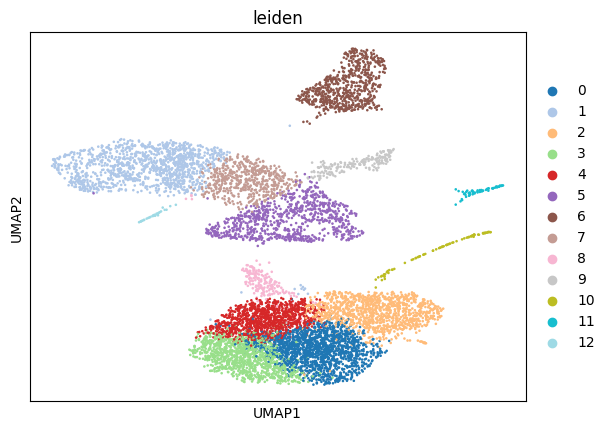

In [99]:
sc.pl.umap(adata, color=['leiden'])

## Map leiden -> ZMAP_CellType annotations

In [ ]:
# Mapping and coloring for approximate CellType-level annotations

leiden_to_ZMAP_CellType = {
    "0":  "yolk syncitial layer",
    "1":  "presomitic meso",
    "2":  "yolk syncitial layer",
    "3":  "yolk syncitial layer",
    "4":  "yolk syncitial layer",
    "5":  "neurectoderm progen",
    "6":  "endoderm progen",
    "7":  "tailbud meso",
    "8":  "ccng-mito high",
    "9":  "notochord",
    "10": "enveloping layer",
    "11": "hatching gland",
    "12": "forerunner cells",
}

adata.uns['ZMAP_ysl_CellType_colormap'] = {
 'endoderm progen': '#ffa52f',
 'forerunner cells': '#c49e72',
 'hatching gland': '#fd1500',
 'neurectoderm progen': '#6967af',
 'notochord': '#932d1a',
 'enveloping layer': '#216701',
 'presomitic meso': '#a55949',
 'tailbud meso': '#ff5238',
 'yolk syncitial layer': '#e1cd9c',
 'ccng-mito high': 'grey',
}

adata.obs["ZMAP_CellType_mapped_ccng"] = (adata.obs["leiden"].astype(str).map(leiden_to_ZMAP_CellType))

In [ ]:
# Mapping and coloring for approximate CellType-level annotations

leiden_to_ZMAP_CellType = {
    "0":  "yolk syncitial layer",
    "1":  "presomitic meso",
    "2":  "yolk syncitial layer",
    "3":  "yolk syncitial layer",
    "4":  "yolk syncitial layer",
    "5":  "neurectoderm progen",
    "6":  "endoderm progen",
    "7":  "tailbud meso",
    "8":  "yolk syncitial layer",
    "9":  "notochord",
    "10": "enveloping layer",
    "11": "hatching gland",
    "12": "forerunner cells",
}

adata.uns['ZMAP_ysl_CellType_colormap'] = {
 'endoderm progen': '#ffa52f',
 'forerunner cells': '#c49e72',
 'hatching gland': '#fd1500',
 'neurectoderm progen': '#6967af',
 'notochord': '#932d1a',
 'enveloping layer': '#216701',
 'presomitic meso': '#a55949',
 'tailbud meso': '#ff5238',
 'yolk syncitial layer': '#e1cd9c',
}

adata.obs["ZMAP_CellType_mapped"] = (adata.obs["leiden"].astype(str).map(leiden_to_ZMAP_CellType))

In [ ]:
# Mapping and coloring for approximate Layer-level annotations

leiden_to_ZMAP_GermLayer = {
    "0":  "yolk syncitial layer",
    "1":  "embryonic",
    "2":  "yolk syncitial layer",
    "3":  "yolk syncitial layer",
    "4":  "yolk syncitial layer",
    "5":  "embryonic",
    "6":  "embryonic",
    "7":  "embryonic",
    "8":  "ccng-mito high",
    "9":  "embryonic",
    "10": "enveloping layer",
    "11": "embryonic",
    "12": "embryonic",
}

adata.uns['ZMAP_ysl_GermLayer_colormap'] = {
 'embryonic': 'lightgrey',
 'enveloping layer': 'lightgrey',
 'yolk syncitial layer': '#1f77b4',
 'ccng-mito high': 'lightgrey',
}

adata.obs["ZMAP_GermLayer_mapped"] = (adata.obs["leiden"].astype(str).map(leiden_to_ZMAP_GermLayer))

## Assess overall proportion of YSL vs embryo

In [ ]:
adata.obs["ZMAP_CellType_mapped_ccng"].value_counts()

,count
ZMAP_CellType_mapped_ccng,
yolk syncitial layer,4823
presomitic meso,1225
neurectoderm progen,829
endoderm progen,667
tailbud meso,543
ccng-mito high,194
notochord,183
enveloping layer,82
hatching gland,59


In [ ]:
print(len(adata))

8636


In [ ]:
x=4823/8636
x

0.5584761463640574

## Plot ZMAP UMAPs

[ZMAP —] Saved figure:
 - zmap_predict/ZMAP_CellType_predicted.png
 - zmap_predict/ZMAP_CellType_predicted.pdf


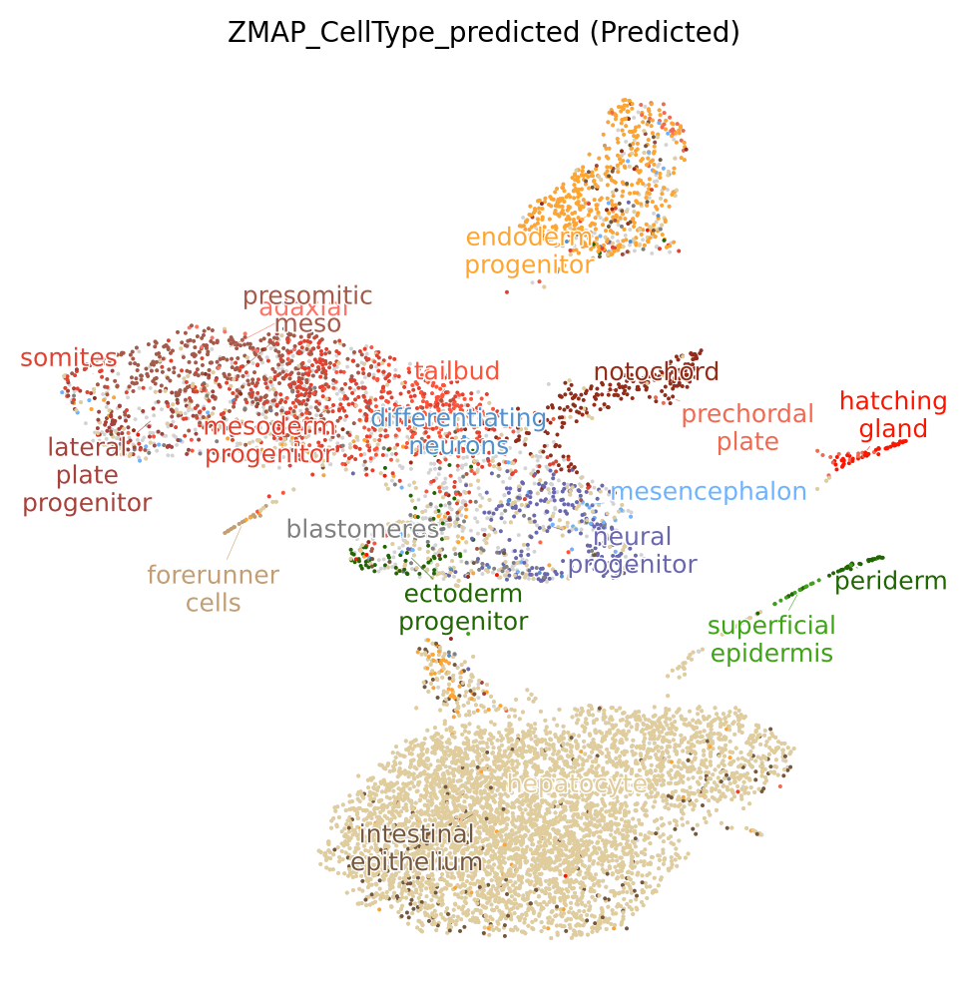

In [ ]:
from zmap.predict import plot_embedding_with_ondata_labels


(f, ax1, ax2) = zmap.predict.plot_embedding_with_ondata_labels(
    adata, adata,
    color_key="ZMAP_CellType_predicted",
    #palette=adata.uns["ZMAP_colormap_T28"],
    figsize=(6, 6),
    dpi=200,
    show_labels=True,
    show_time_strip=False,
    legend_fontsize=9,
    recolor_labels_from_palette=True,
    ref_size=8, ref_alpha=1,
    test_size=8, test_alpha=1,
    return_ax=True, show=True)

f.savefig(base_path+'figs/'+'ZMAP_CellType_predicted.pdf', dpi=600, bbox_inches="tight")

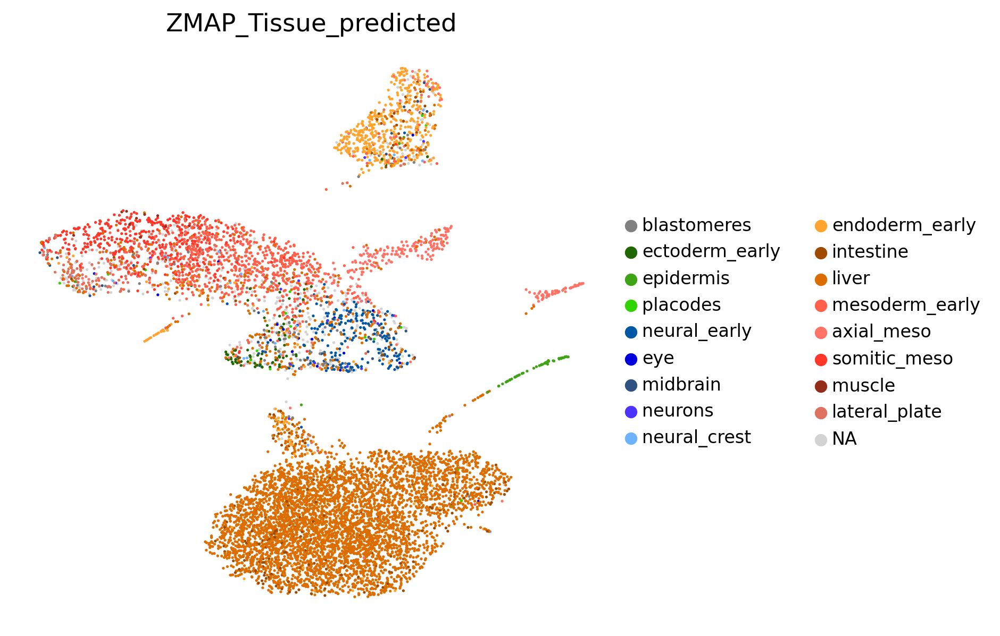

In [ ]:
from matplotlib import legend
sc.set_figure_params(figsize=(6, 6), dpi=120)

col = "ZMAP_Tissue_predicted"
order = [x for x in adata.uns['ZMAP_Tissue_order']
         if x in adata.obs[col].cat.categories]
adata.obs[col] = adata.obs[col].cat.reorder_categories(order, ordered=True)

f = sc.pl.umap(adata,
               color='ZMAP_Tissue_predicted',
               palette=adata.uns['ZMAP_colormap_T28'],
               s=10, frameon=False, legend_fontsize=10,
               show=False,
               return_fig=True)

#f.savefig('ZMAP_CellType.pdf', bbox_inches="tight")

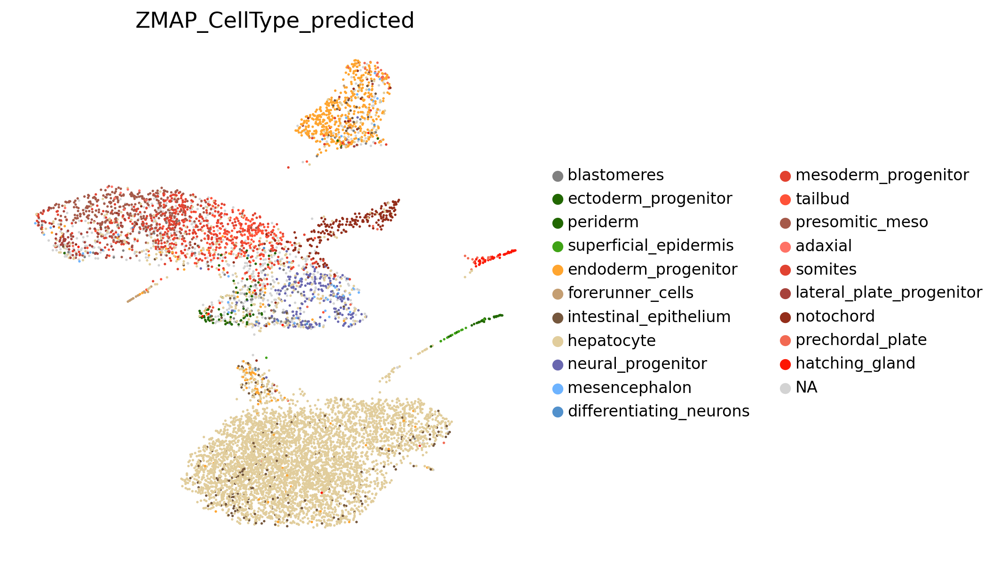

In [ ]:
from matplotlib import legend
sc.set_figure_params(figsize=(6, 6), dpi=120)

col = "ZMAP_CellType_predicted"
order = [x for x in adata.uns['ZMAP_CellType_order']
         if x in adata.obs[col].cat.categories]
adata.obs[col] = adata.obs[col].cat.reorder_categories(order, ordered=True)

f = sc.pl.umap(adata,
               color='ZMAP_CellType_predicted',
               palette=adata.uns['ZMAP_colormap_C79'],
               s=10, frameon=False, legend_fontsize=10,
               show=False,
               return_fig=True)

#f.savefig('ZMAP_CellType.pdf', bbox_inches="tight")

## Plot Annotated UMAPs

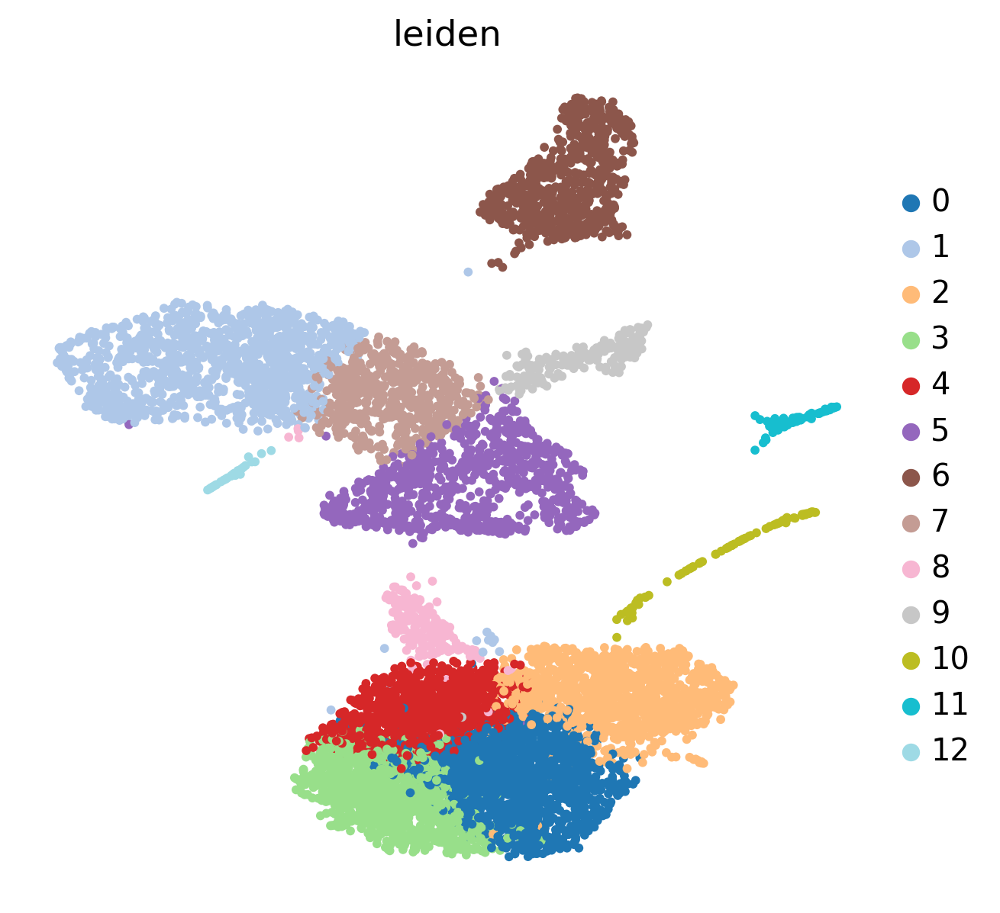

In [ ]:
from matplotlib import legend
sc.set_figure_params(figsize=(6, 6), dpi=120)

f = sc.pl.umap(adata,
               color='leiden',
               s=50, frameon=False, legend_fontsize=12,
               show=False,
               return_fig=True)

f.savefig(base_path+'figs/'+'YSL_leiden.png', dpi=200, bbox_inches="tight")

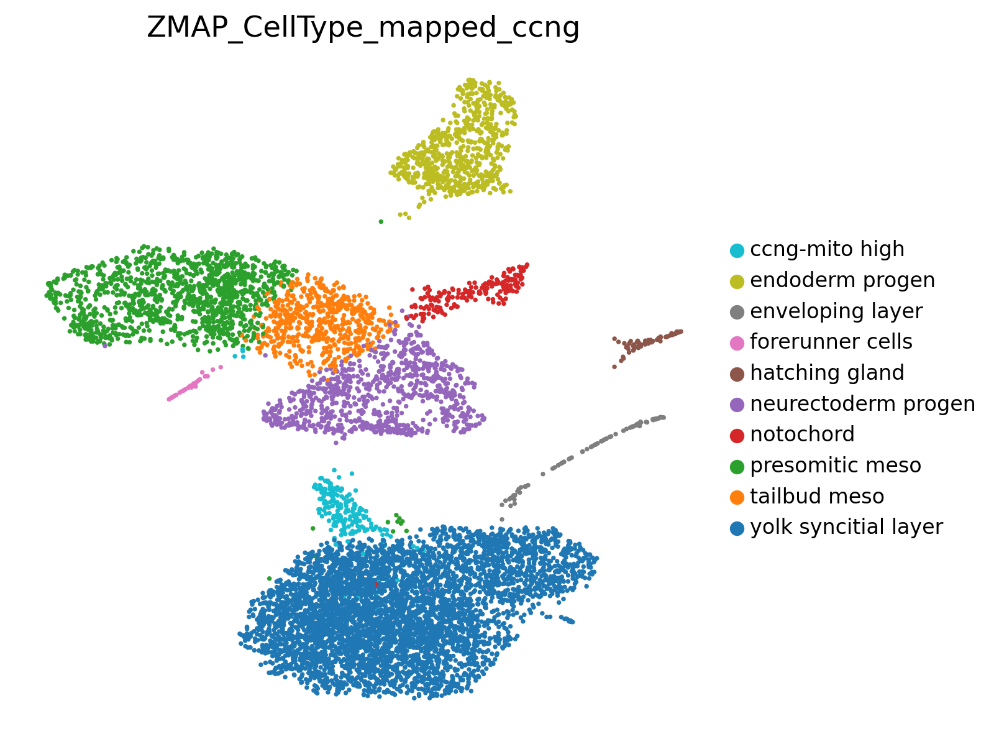

In [ ]:
f = sc.pl.umap(adata,
               color='ZMAP_CellType_mapped_ccng',
               s=20, frameon=False, legend_fontsize=10,
               palette='tab10_r',
               #palette=adata.uns['ZMAP_ysl_CellType_colormap_ccng'],
               show=False,
               return_fig=True)

f.savefig(base_path+'figs/'+'ZMAP_CellType_mapped_ccng.pdf', dpi=600, bbox_inches="tight")

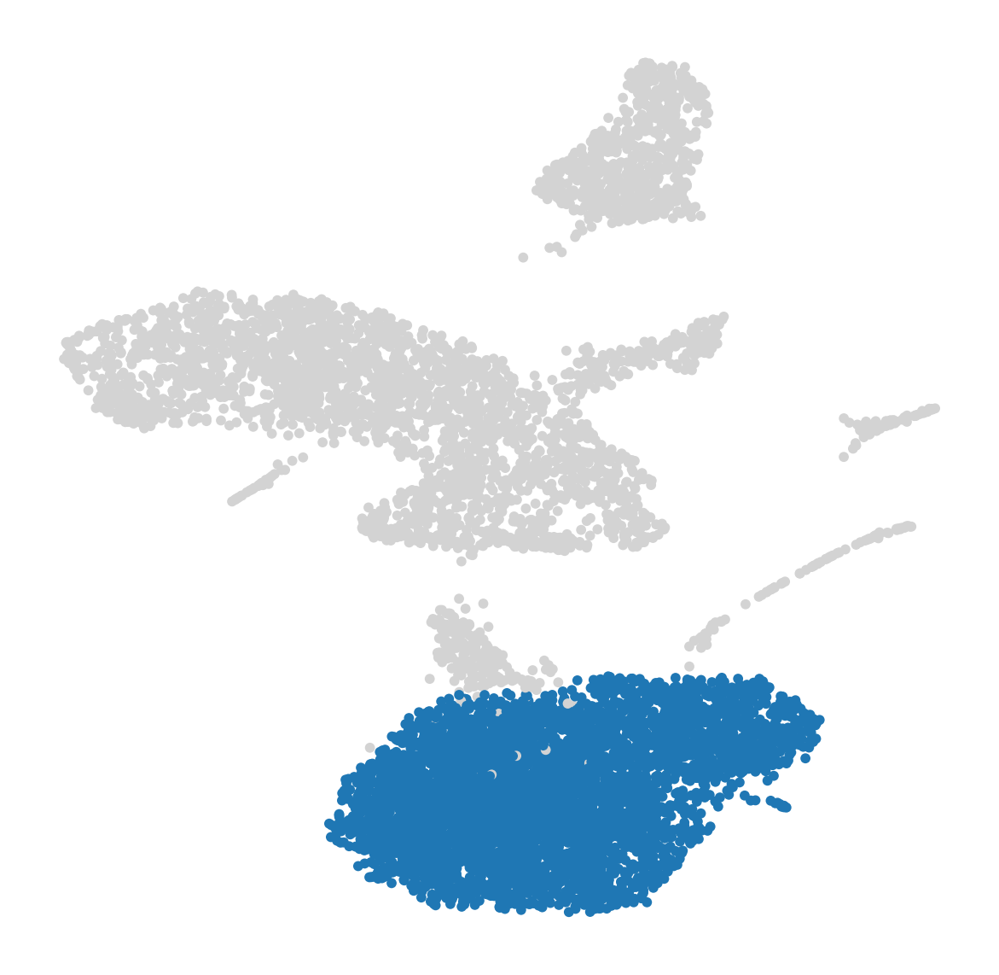

In [ ]:
f = sc.pl.umap(adata,
               color='ZMAP_GermLayer_mapped',
               s=50, frameon=False, legend_fontsize=10,
               palette=adata.uns['ZMAP_ysl_GermLayer_colormap'],
               show=False, legend_loc=None, title='',
               return_fig=True)

f.savefig(base_path+'figs/'+'ZMAP_CellType_mapped_subset_mask.pdf', dpi=600, bbox_inches="tight")

## Assess time prediction

[ZMAP —] Saved time plot: zmap_predict/ZMAP_CellType/ZMAP_CellType_time_distribution.png


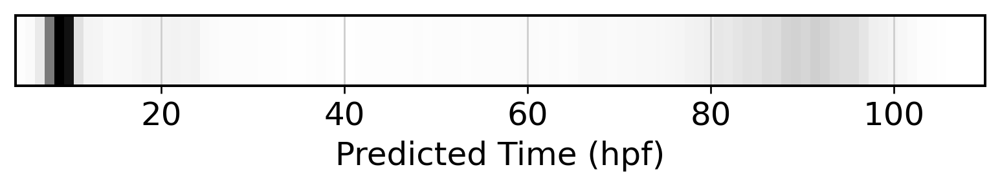

,ZMAP_time_id_predicted
0,8.0


In [ ]:
zmap.predict.plot_time(adata, save=True)
adata.obs['ZMAP_time_id_predicted'].mode()

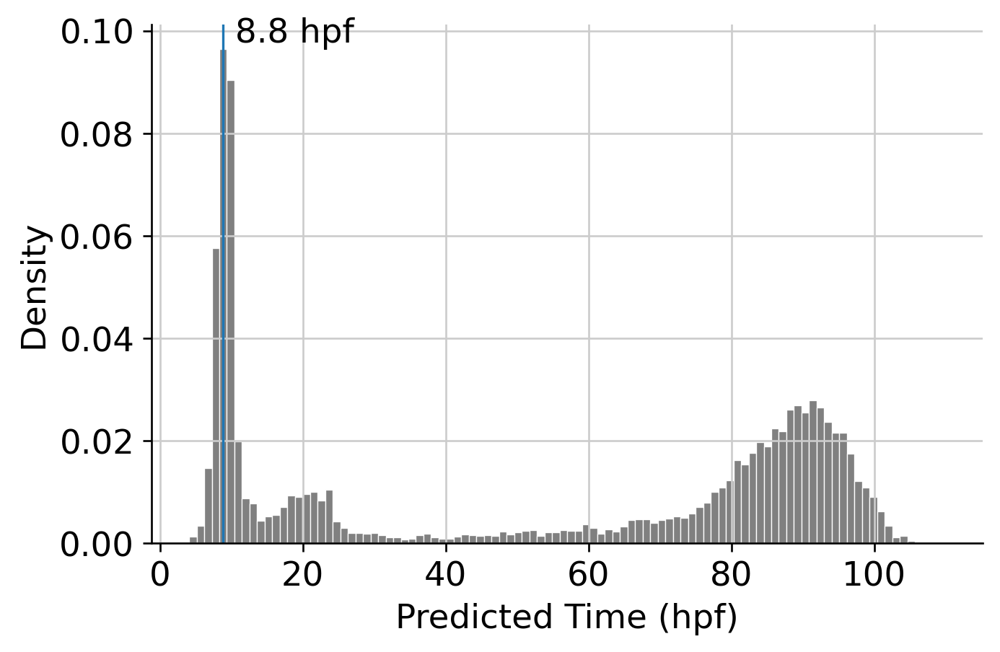

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = adata.obs["ZMAP_time_id_predicted"].dropna()

fig, ax = plt.subplots(figsize=(6, 4))

density, bin_edges, _ = ax.hist(
    x,
    bins=100,
    density=True,
    color="grey",
    edgecolor="white",
    linewidth=0.4
)

# Center of the highest histogram bin
peak_idx = np.argmax(density)
peak_x = (bin_edges[peak_idx] + bin_edges[peak_idx + 1]) / 2
peak_y = density[peak_idx]

ax.axvline(peak_x, linestyle="-", linewidth=1)
ax.annotate(
    f"{peak_x:.1f} hpf",
    xy=(peak_x, peak_y),
    xytext=(5, 0),
    textcoords="offset points",
    ha="left",
    va="bottom")

ax.set_xlabel("Predicted Time (hpf)")
ax.set_ylabel("Density")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## Assess per-cluster predictions

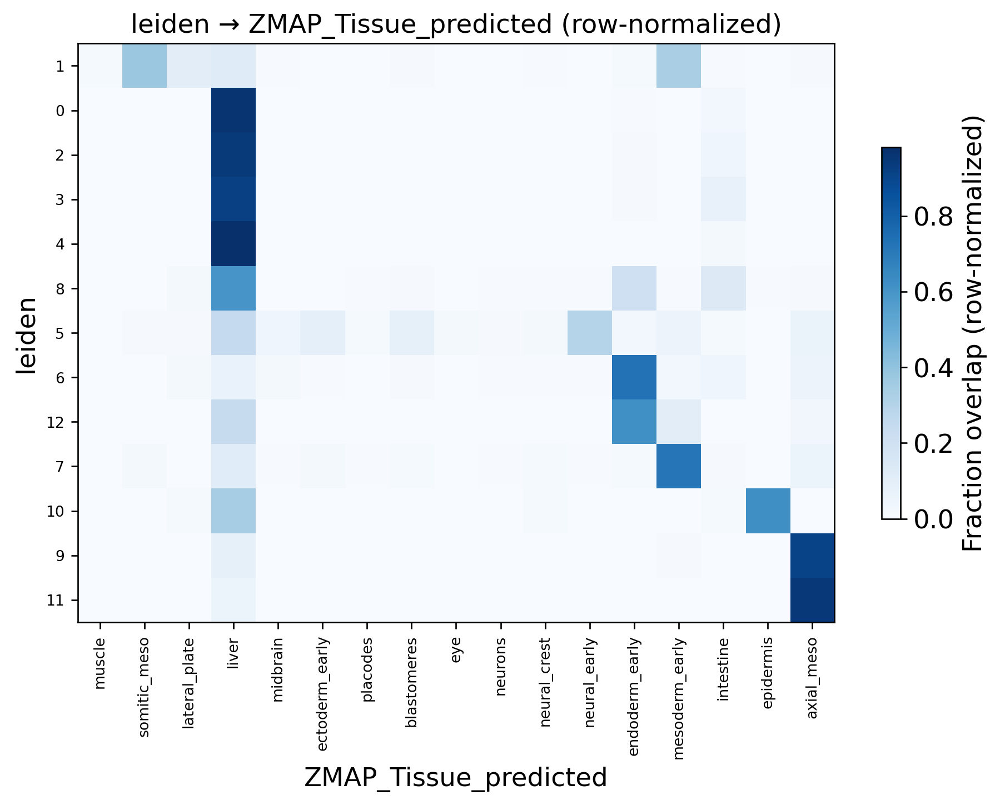

,top_match
leiden,
0,liver
1,somitic_meso
2,liver
3,liver
4,liver
5,neural_early
6,endoderm_early
7,mesoderm_early
8,liver


In [ ]:
zmap.predict.plot_overlap_matrix(adata, label_space='ZMAP_Tissue')

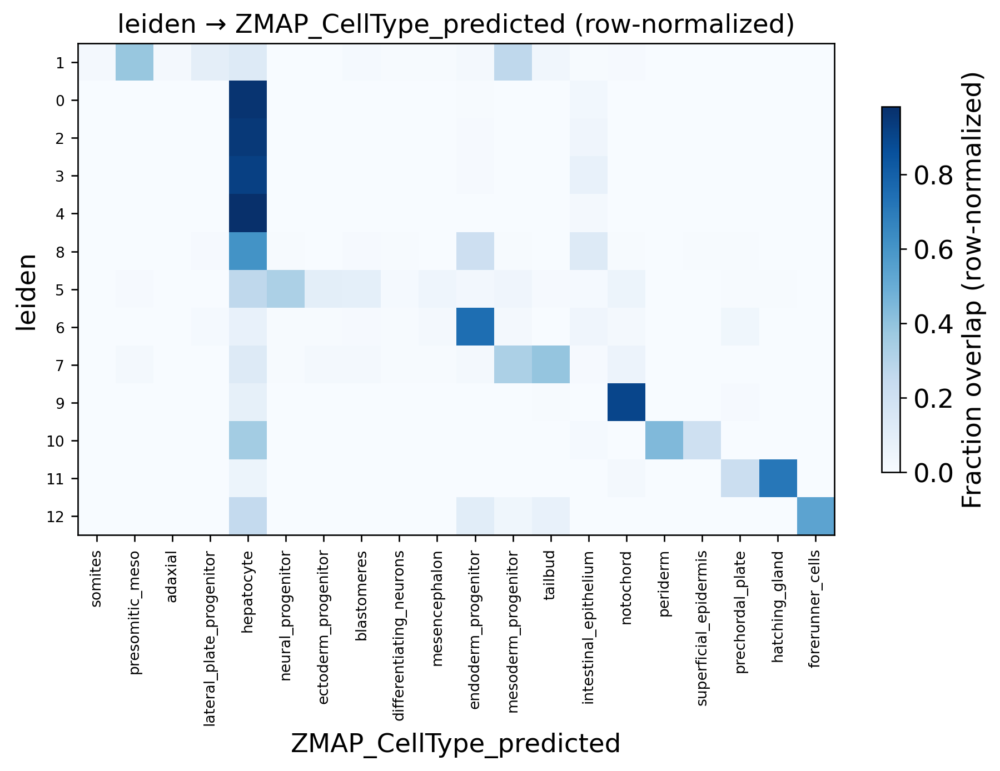

,top_match
leiden,
0,hepatocyte
1,presomitic_meso
2,hepatocyte
3,hepatocyte
4,hepatocyte
5,neural_progenitor
6,endoderm_progenitor
7,tailbud
8,hepatocyte


In [ ]:
zmap.predict.plot_overlap_matrix(adata, label_space='ZMAP_CellType')


## Overlay YSL Gene Scores

202


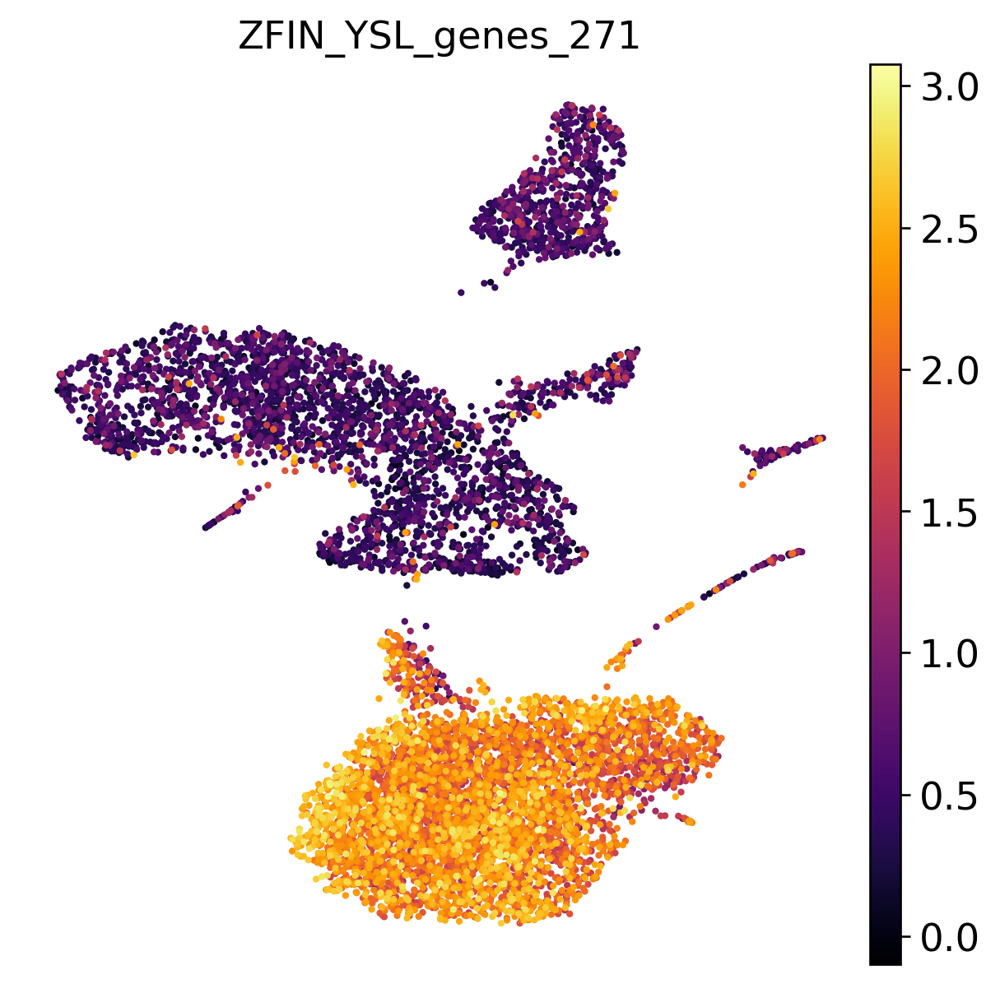







In [ ]:
sc.set_figure_params(figsize=(6, 6), dpi=120)
score_name = 'ZFIN_YSL_genes_271' # YSL marker list compiled by Xu et al 2012
gene_list = ['a2ml','acbd7','acp5a','acsl4l','adora2ab','adora2b','ak3','aldob','amt','angptl3','anxa1a','anxa6','anxa11b','aplnra','apoa1','apoa4','apobl','apoeb','arl6ip5a','atic','atp1b3a','atp2b1a','atp6ap1','bcl2l10','bmp2b','bty','cahz','cask','cd36','cd164','cdh2','cebpa','cebpb','ckmt1','clcn7','cldni','cndp2','cnn2','cpeb4','cpn1','cpvl','creb3l3l','crlf3','csad','csnk1db','csrnp1b','ctage5','ctbs','ctnnb1','ctsba','ctsc','ctsl1a','ctssb.2','cyp11a1','dao.1','dao.3','degs1','dharma','dhrs3b','dnajb11','dnajc3','dpp7','dusp1','dusp6','echs1','efnb1','elovl5','entpd1','esrp2','fabp1b.1','fam116b','fbp1b','fbxo32','fcho2','fdps','fgf17','foxa3','foxh1','fpgs','fstl1b','ftr82','fuca1','fuca2','fzd7a','gadd45ba','gadd45bb','gadd45g','gamt','gata5','gatm','gats','gbx1','ggcx','glud1a','gmppab','gnsb','gpib','gpr137bb','gpx4a','gsc','hao2','has2','hey1','hhex','hkdc1','hnf4a','hnf4b','hsd3b1','hsp90b1','hspa5','hspd1','icmt','ifi30','insig1','itih2','ivns1abpa','katnal1','kdelr2','lamc1','lamp2','lmbrd2a','lmo4b','loxl3b','lrrc15','mat1a','mdm2','mfsd4a','micall2','mknk2a','mogat2','mpp1','mst1','mthfd1','mtp','mvp','mxtx1','mxtx2','ndr1','ndr2','neo1','nkd1','npc2','nrp2b','nt5dc2','ntla','optn','osbpl2','otop1','paics','pawrl','pck2','pdgfra','pdlim1','pgd','pgm1','phf20b','phospho1','pik3ip1','pitpna','pla2g12b','plbd1','plod3','pmepa1','ppat','ppp1r3ca','prdm1a','prkaa1','psap','pth2r','rab5b','rbp4l','rdh10b','rgr','rgs4','rnpep','rrbp1','rrp12','rtn1a','rundc3b','sall1a','scarb1','scpep1','sec61al1','sec61al2','sept9a','serpina1l','sesn3','sfxn1','shcbp1','shmt1','sid4','sipa1l1','slc3a2','slc7a6','slc11a2','slc16a1','slc17a9b','slc26a1','slc27a2','slc31a1','slc37a4a','slc38a7','slc39a1','slc47a1','smtnl','snai1a','sox32','spns2','ssr1','st3gal2l','stard3','sult2st1','tfa','tfe3a','tgfbr2','tkt','tmed1a','tmem56b','tmem49','tnfaip8l2b','tram1','tsku','ugcg','vox','xbp1','xirp1','ypel3','zgc:55891','zgc:55813','zgc:56041','zgc:56530','zgc:56585','zgc:63523','zgc:63767','zgc:77395','zgc:77799','zgc:85683','zgc:86738','zgc:86776','zgc:91860','zgc:91870','zgc:91909','zgc:91936','zgc:92040','zgc:92470','zgc:92481','zgc:92765','zgc:92903','zgc:100963','zgc:101000','zgc:101071','zgc:101540','zgc:101616','zgc:101780','zgc:101876','zgc:103700','zgc:110246','zgc:110409','zgc:110418','zgc:110447','zgc:110692','zgc:112265','zgc:112994','zgc:114041','zgc:136410','zgc:152830','zgc:153913','zgc:171663','zgc:174888','zgc:193613','zgc:194131']
gene_list = [gene for gene in gene_list if gene in adata.var_names]
print(len(gene_list))

sc.tl.score_genes(adata,
                  gene_list,
                  score_name=score_name,
                  layer='tpm',
                  ctrl_as_ref=True,
                  ctrl_size=50,
                  n_bins=25)

f = sc.pl.umap(adata,
               color=score_name,
               cmap='inferno',
               s=25, alpha=1,
               #vmax=4, vmin=0,
               frameon=False,
               show=True,
               return_fig=True)

f2 = sc.pl.matrixplot(adata,
                      var_names=gene_list,
                      groupby='ZMAP_CellType_mapped',
                      standard_scale='var', layer='tpm',
                      cmap='inferno',
                      dendrogram=True,
                      swap_axes=False,
                      return_fig=True)

f3 = sc.pl.dotplot(adata,
                   var_names=gene_list,
                   groupby='ZMAP_CellType_mapped',
                   standard_scale='var', layer='tpm',
                   cmap='inferno',
                   dendrogram=True,
                   swap_axes=False,
                   return_fig=False)

f.savefig(base_path+'figs/'+'YSL_scores_XU271.pdf', dpi=600, bbox_inches="tight")
f.savefig(base_path+'figs/'+'YSL_scores_XU271.png', dpi=600, bbox_inches="tight")
f2.savefig(base_path+'figs/'+'YSL_scores_XU271_hmap.pdf', dpi=600, bbox_inches="tight")


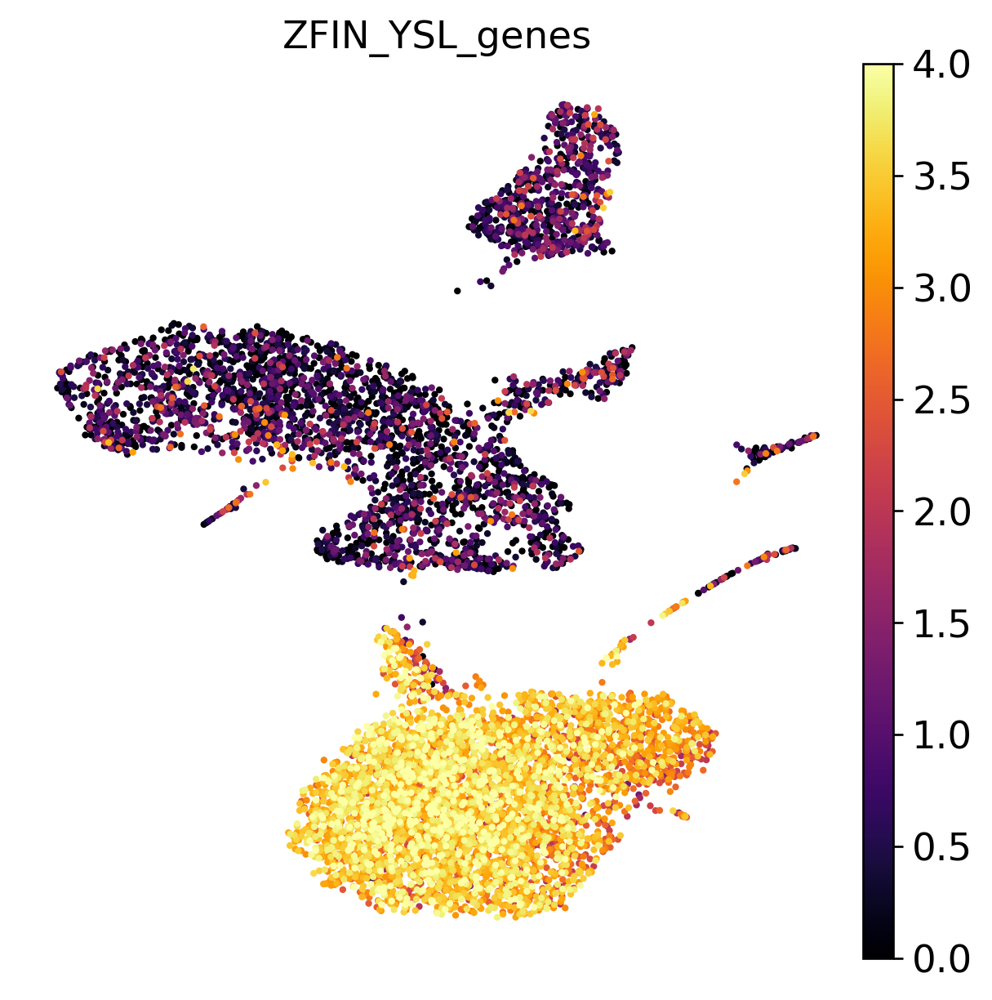

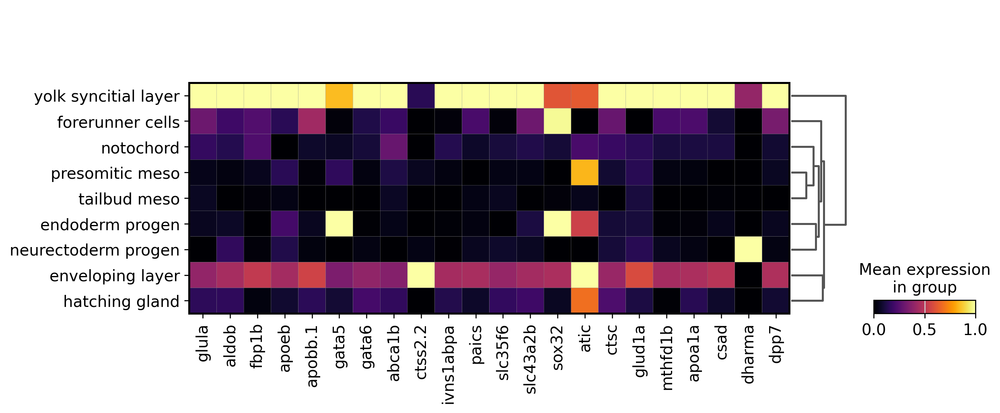

In [ ]:
sc.set_figure_params(figsize=(6, 6), dpi=120)
score_name = 'ZFIN_YSL_genes' # top 25 ranked genes
gene_list = ['glula','aldob','fbp1b','apoeb','apobb.1','gata5','gata6','abca1b','ctss2.2','ivns1abpa','paics','slc35f6','slc43a2b','sox32','atic','ctsc','glud1a','mthfd1b','apoa1a','csad','dharma','dpp7']

sc.tl.score_genes(adata,
                  gene_list,
                  score_name=score_name,
                  layer='tpm',
                  ctrl_as_ref=True,
                  ctrl_size=50,
                  n_bins=25)

f = sc.pl.umap(adata,
               color=score_name,
               cmap='inferno',
               s=25, alpha=1,
               vmax=4, vmin=0,
               frameon=False,
               show=True,
               return_fig=True)

f2 = sc.pl.matrixplot(adata,
                      var_names=gene_list,
                      groupby='ZMAP_CellType_mapped',
                      standard_scale='var', layer='tpm',
                      cmap='inferno',
                      dendrogram=True,
                      swap_axes=False,
                      return_fig=False)

#f.savefig(base_path+'figs/'+'YSL_scores_zfin.pdf', dpi=600, bbox_inches="tight")
#f2.savefig(base_path+'figs/'+'YSL_scores_zfin_hmap.pdf', dpi=600, bbox_inches="tight")


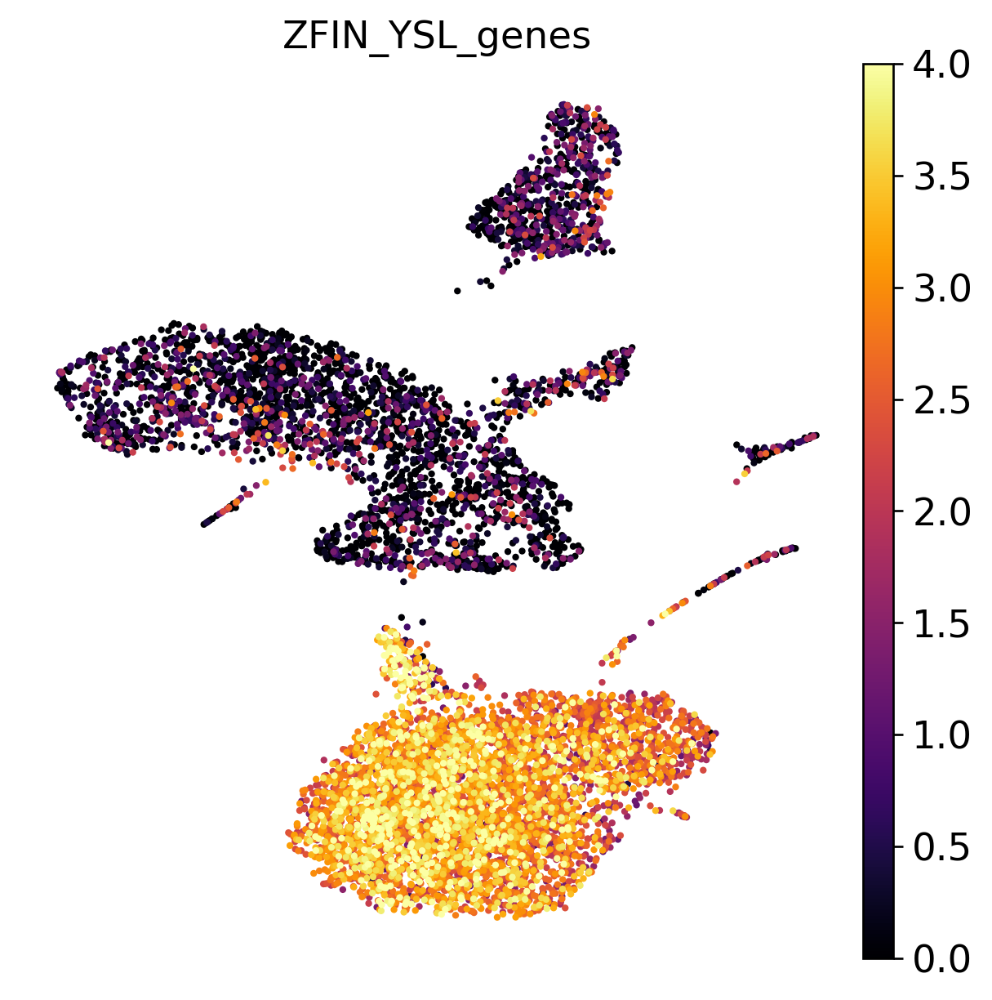

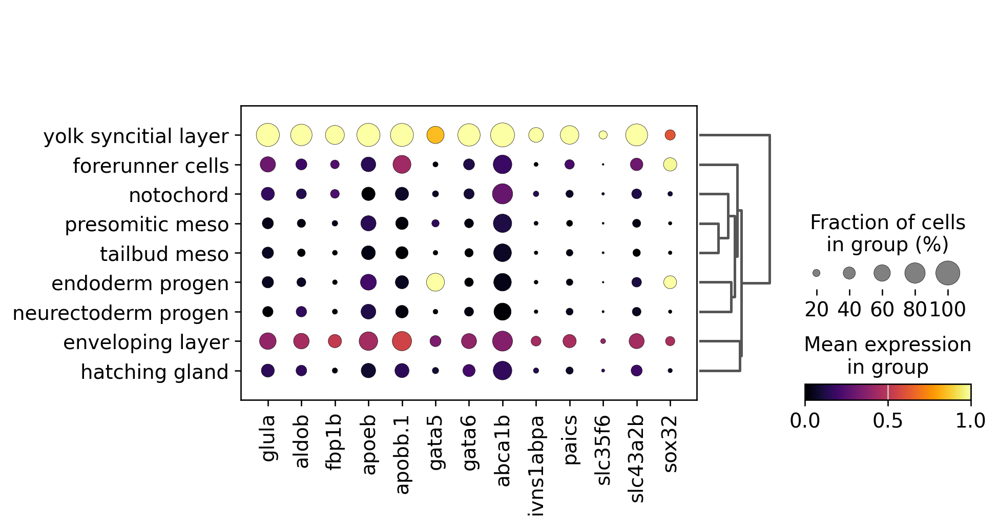

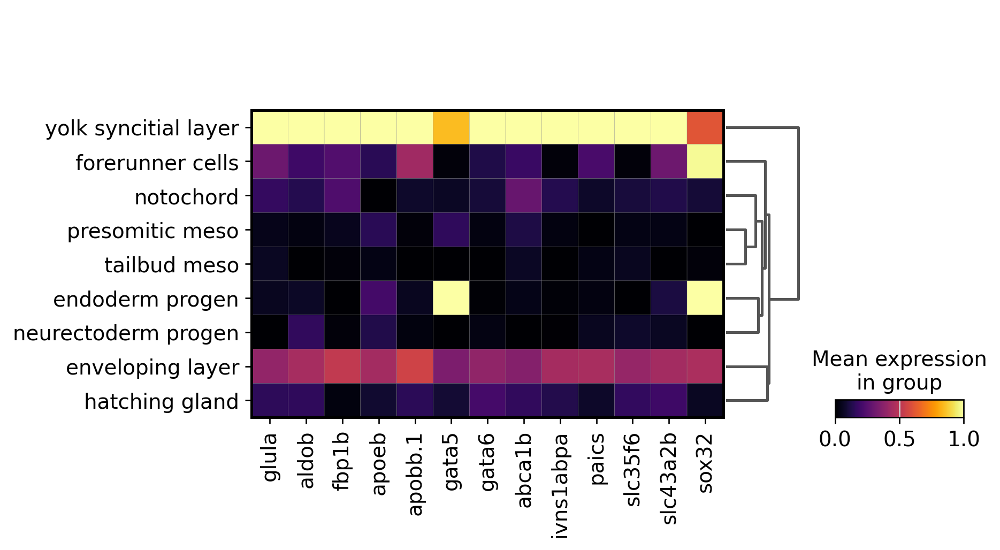

In [ ]:
sc.set_figure_params(figsize=(6, 6), dpi=120)
score_name = 'ZFIN_YSL_genes' # genes with >10 figures
gene_list = ['glula','aldob','fbp1b','apoeb','apobb.1','gata5','gata6','abca1b','ivns1abpa','paics','slc35f6','slc43a2b','sox32']

sc.tl.score_genes(adata,
                  gene_list,
                  score_name=score_name,
                  layer='tpm',
                  ctrl_as_ref=True,
                  ctrl_size=50,
                  n_bins=25)

f = sc.pl.umap(adata,
               color=score_name,
               cmap='inferno',
               s=25, alpha=1,
               vmax=4, vmin=0,
               frameon=False,
               show=True,
               return_fig=True)

f2 = sc.pl.matrixplot(adata,
                      var_names=gene_list,
                      groupby='ZMAP_CellType_mapped',
                      standard_scale='var', layer='tpm',
                      cmap='inferno',
                      dendrogram=True,
                      swap_axes=False,
                      return_fig=True)

f3 = sc.pl.dotplot(adata,
                   var_names=gene_list,
                   groupby='ZMAP_CellType_mapped',
                   standard_scale='var', layer='tpm',
                   cmap='inferno',
                   dendrogram=True,
                   swap_axes=False,
                   return_fig=False)

f.savefig(base_path+'figs/'+'YSL_scores_zfin.pdf', dpi=600, bbox_inches="tight")
f2.savefig(base_path+'figs/'+'YSL_scores_zfin_hmap.pdf', dpi=600, bbox_inches="tight")


## RankGenesGroups: Leiden

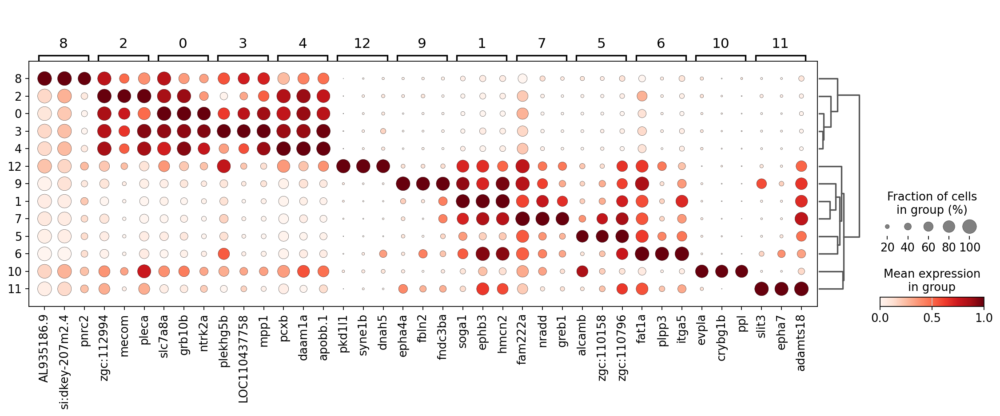

In [ ]:
sc.tl.rank_genes_groups(adata, 'leiden', method='wilcoxon')
sc.set_figure_params(figsize=(6, 6), dpi=80)
sc.pl.rank_genes_groups_dotplot(adata, n_genes=3, standard_scale='var')

In [ ]:
import pandas as pd
import scanpy as sc

top_x = 50

groups = adata.uns["rank_genes_groups"]["names"].dtype.names

top_genes_df = pd.DataFrame({
    group: sc.get.rank_genes_groups_df(adata, group=group).head(top_x)["names"].values
    for group in groups
})

top_genes_df

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,slc7a8a,soga1,zgc:112994,plekhg5b,pcxb,alcamb,fat1a,fam222a,AL935186.9,epha4a,evpla,slit3,pkd1l1
1,grb10b,ephb3,mecom,LOC110437758,daam1a,zgc:110158,plpp3,nradd,si:dkey-207m2.4,fbln2,crybg1b,epha7,syne1b
2,ntrk2a,hmcn2,pleca,mpp1,apobb.1,zgc:110796,itga5,greb1,pnrc2,fndc3ba,ppl,adamts18,dnah5
3,inpp4b,rbm38,hs3st2,spred2b,lrba,xylt1,lzts2a,itgb5,hnrnpa0l,kirrel3l,krt5,si:ch211-163l21.10,cgnl1
4,col14a1a,tbx16,rgs3a,trak1a,bcl9l,celsr1a,phldb1b,rbm38,hspa8,large2,si:ch211-166a6.5,frzb,kif26ab
5,cdh6,hspa12a,eya1,atp2b1a,nrp1a,adgrl2a,ptprfb,wnt5b,si:ch73-281n10.2,admp,eppk1,elovl6,bicc2
6,macf1a,efnb2b,rap1gap,lrrc4ba,sb:cb37,kpnb3,dnmt3bb.1,ephb4a,NC_002333.4,plod2,ptpn13,fzd8b,quo
7,wnk4b,meis1b,plecb,st3gal3b,pck2,tiam1b,sema4c,il17rd,nr0b2a,nrip1a,krt4,pawr,pmfbp1
8,ctsc,nectin1b,glra1,rmdn2,LOC100006868,unc5b,chsy1,lef1,myh9a,epha2a,gmds,six7,tp53i11b
9,abtb2a,fn1a,bmp16,neurl1b,gatm,jarid2b,lmo4a,cdx1a,NC_002333.17,igsf3,krt97,si:ch211-163l21.8,pacrg


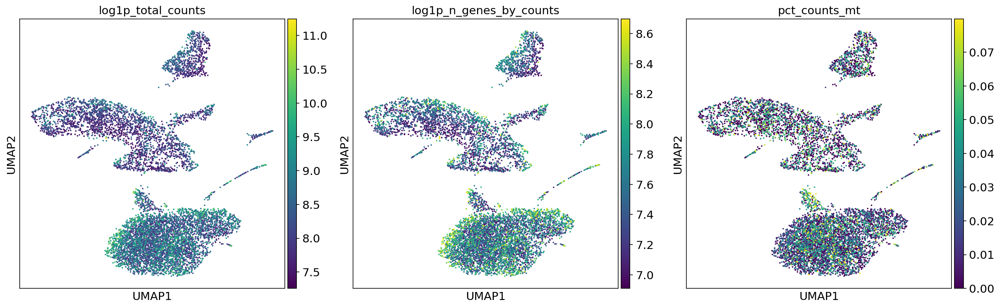

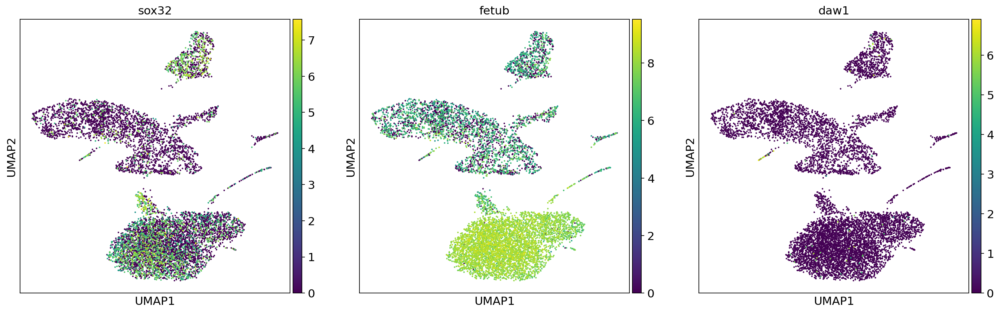

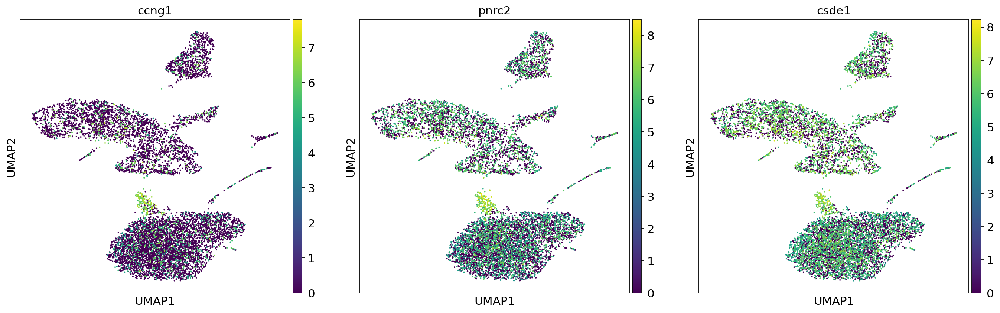

In [ ]:
sc.pl.umap(adata, color=['log1p_total_counts','log1p_n_genes_by_counts','pct_counts_mt'])
sc.pl.umap(adata, color=['sox32','fetub','daw1'])
sc.pl.umap(adata, color=['ccng1','pnrc2','csde1'])

## RankGenesGroups: ZMAP Annotations

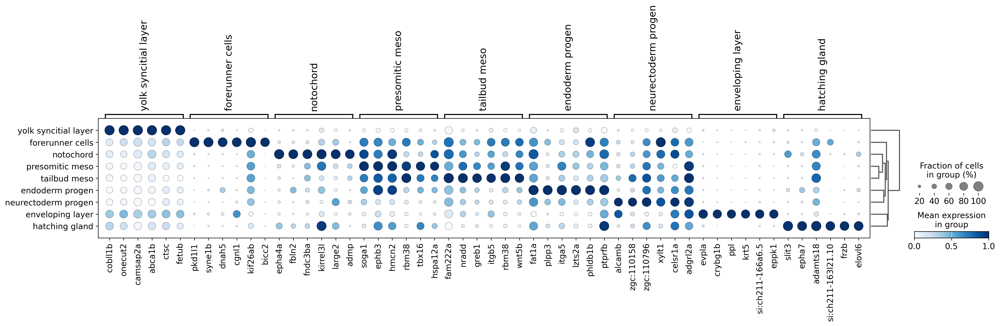

In [ ]:
sc.tl.dendrogram(adata, groupby='ZMAP_CellType_mapped')
#sc.tl.rank_genes_groups(adata, 'ZMAP_CellType_mapped', method='wilcoxon')
sc.set_figure_params(figsize=(6, 6), dpi=120)
f=sc.pl.rank_genes_groups_dotplot(adata,
                                  n_genes=6,
                                  standard_scale='var',
                                  cmap='Blues',
                                  show=False,
                                  return_fig=True)

#f.savefig(base_path+'figs/'+'ZMAP_CellType_mapped_dotplot.pdf', dpi=600, bbox_inches="tight")

In [ ]:
import pandas as pd
import scanpy as sc

groups = adata.uns["rank_genes_groups"]["names"].dtype.names

deg_sig_df = pd.concat(
    [
        sc.get.rank_genes_groups_df(adata, group=group)
        .query("pvals_adj < 0.05 and logfoldchanges > 1")
        .sort_values("logfoldchanges", ascending=False)
        .assign(cell_type=group, rank=lambda df: range(1, len(df) + 1))
        for group in groups
    ],
ignore_index=True)

deg_sig_df = deg_sig_df.rename(
    columns={
        "names": "gene",
        "logfoldchanges": "log2fc",
        "pvals_adj": "adjusted_pvalue",
    }
)[["cell_type", "rank", "gene", "log2fc", "adjusted_pvalue"]]

deg_sig_df.to_csv("significant_enriched_DEGs_per_cell_type.csv", index=False)

deg_sig_df

,cell_type,rank,gene,log2fc,adjusted_pvalue
0,endoderm progen,1,plpp3,9.378916,0.000000e+00
1,endoderm progen,2,arhgap36,8.940364,1.269668e-271
2,endoderm progen,3,met,8.924546,1.752909e-211
3,endoderm progen,4,sema4c,8.507164,5.080817e-300
4,endoderm progen,5,gpm6ab,8.115829,1.343428e-225
...,...,...,...,...,...
10739,yolk syncitial layer,3364,veph1,1.003676,2.318170e-04
10740,yolk syncitial layer,3365,si:ch211-242b18.1,1.003672,1.988962e-06
10741,yolk syncitial layer,3366,myo19,1.003463,7.550119e-04
10742,yolk syncitial layer,3367,cbfb,1.002629,1.158170e-04


In [ ]:
ysl_genes = (
    deg_sig_df.loc[deg_sig_df["cell_type"] == "yolk syncitial layer"]
    .sort_values("log2fc", ascending=False)["gene"]
    .tolist()
)

print(len(ysl_genes))
ysl_genes[0:10]

3368


['katnal1',
 'bhmt',
 'mvp',
 'gatm',
 'a1cf',
 'plbd1',
 'anxa6',
 'hnf4b',
 'epas1a',
 'sema4gb']

In [ ]:
import pandas as pd
import scanpy as sc

groups = adata.uns["rank_genes_groups"]["names"].dtype.names

deg_sig_df_depleted = pd.concat(
    [
        sc.get.rank_genes_groups_df(adata, group=group)
        .query("pvals_adj < 0.05 and logfoldchanges < -1")
        .sort_values("logfoldchanges", ascending=True)
        .assign(cell_type=group, rank=lambda df: range(1, len(df) + 1))
        for group in groups
    ],
    ignore_index=True,
)

deg_sig_df_depleted = deg_sig_df_depleted.rename(
    columns={
        "names": "gene",
        "logfoldchanges": "log2fc",
        "pvals_adj": "adjusted_pvalue",
    }
)[["cell_type", "rank", "gene", "log2fc", "adjusted_pvalue"]]

deg_sig_df_depleted.to_csv("significant_depleted_DEGs_per_cell_type.csv", index=False)

deg_sig_df_depleted

,cell_type,rank,gene,log2fc,adjusted_pvalue
0,endoderm progen,1,slc2a9l2,-28.641577,2.295222e-02
1,endoderm progen,2,erlin2,-5.443105,1.137538e-50
2,endoderm progen,3,slc12a1,-4.999109,4.248668e-85
3,endoderm progen,4,mvp,-4.988122,4.101211e-134
4,endoderm progen,5,gatm,-4.946032,4.372801e-107
...,...,...,...,...,...
12812,yolk syncitial layer,2950,usf1l,-1.002818,8.063973e-03
12813,yolk syncitial layer,2951,paip2b,-1.002357,4.682427e-04
12814,yolk syncitial layer,2952,ints8,-1.001545,4.845322e-121
12815,yolk syncitial layer,2953,adck1,-1.001329,1.347501e-04


In [ ]:
ysl_genes_depleted = (
    deg_sig_df_depleted.loc[deg_sig_df_depleted["cell_type"] == "yolk syncitial layer"]
    .sort_values("log2fc", ascending=True)["gene"]
    .tolist()
)

print(len(ysl_genes_depleted))
ysl_genes_depleted[0:10]

2954


['ror2',
 'igf1ra',
 'adgrl2a',
 'nectin1b',
 'tmem132e',
 'zgc:110796',
 'soga1',
 'ephb3',
 'adamts18',
 'hmcn2']

## YSL GO TERM ENRICHMENT

In [ ]:
!pip install -q gprofiler-official

In [ ]:
import pandas as pd
from gprofiler import GProfiler

def run_enrichment(
    gene_list,
    background,
    organism="drerio",
    sources=("GO:BP", "GO:MF", "KEGG"),
    p_threshold=0.05,
    max_term_size=400,
    output_file="YSL_GO_KEGG_enrichment.csv",
):
    res = GProfiler(return_dataframe=True).profile(
        organism=organism,
        query=list(gene_list),
        background=list(background),
        domain_scope="custom",
        sources=list(sources),
        ordered=False,
        user_threshold=p_threshold,
        significance_threshold_method="fdr",
        no_evidences=False,
    )

    columns = [
        "Database", "TermID", "Term", "FDR", "FoldEnrichment",
        "OverlapGenes", "TermGenes", "QueryGenes", "BackgroundGenes",
        "GeneNames",
    ]

    if res.empty:
        table = pd.DataFrame(columns=columns)
    else:
        res["GeneNames"] = res["intersections"].apply(", ".join)

        res["FoldEnrichment"] = (
            res["intersection_size"] * res["effective_domain_size"]
            / (res["query_size"] * res["term_size"])
        )

        table = (
            res.loc[
                (res["p_value"] < p_threshold)
                & (res["term_size"] <= max_term_size)
            ]
            .rename(columns={
                "source": "Database",
                "native": "TermID",
                "name": "Term",
                "p_value": "FDR",
                "intersection_size": "OverlapGenes",
                "term_size": "TermGenes",
                "query_size": "QueryGenes",
                "effective_domain_size": "BackgroundGenes",
            })[columns]
            .sort_values("FDR")
            .reset_index(drop=True)
        )

    table.to_csv(output_file, index=False)
    return table

In [ ]:
background=adata.var_names.tolist()
len(background)

31859

In [ ]:
ysl_enriched_terms = run_enrichment(gene_list=ysl_genes, background=adata.var_names.tolist())
ysl_enriched_terms.to_csv("YSL_GO_KEGG_enrichment.csv", index=False)
ysl_enriched_terms

,Database,TermID,Term,FDR,FoldEnrichment,OverlapGenes,TermGenes,QueryGenes,BackgroundGenes,GeneNames
0,KEGG,KEGG:04142,Lysosome biogenesis,1.147003e-43,5.090984,99,228,2430,28491,"ctsba, dmxl2, psap, gnsb, igf2r, FIG4, ctss2.1..."
1,KEGG,KEGG:04144,Endocytosis,8.295556e-14,2.919942,65,261,2430,28491,"igf2r, acap3a, nedd4a, rab7b, gbf1, fgfr2, asa..."
2,KEGG,KEGG:04141,Protein processing in endoplasmic reticulum,2.451509e-13,3.532439,47,156,2430,28491,"man1a1, sec24d, wfs1b, RNF5, xbp1, sec61b, atf..."
3,KEGG,KEGG:04140,Autophagy - animal,1.869053e-11,3.210332,46,168,2430,28491,"ctsba, rab7b, atg16l2, ctsla, prkacba, prkacaa..."
4,KEGG,KEGG:04137,Mitophagy - animal,4.152417e-08,3.304231,31,110,2430,28491,"rab7b, si:dkey-238d18.4, tbc1d17, mfn1b, tfe3a..."
...,...,...,...,...,...,...,...,...,...,...
169,KEGG,KEGG:00020,Citrate cycle (TCA cycle),4.385664e-02,2.705698,6,26,2430,28491,"pcxb, suclg1, pcxa, idh3g, ogdha, sucla2"
170,KEGG,KEGG:00565,Ether lipid metabolism,4.529308e-02,2.287745,8,41,2430,28491,"pla2g12b, plpp1a, pld1a, lpcat2, tmem86a, pafa..."
171,GO:BP,GO:0006665,sphingolipid metabolic process,4.683288e-02,3.103595,9,34,2430,28491,"psap, smpd2a, asah2, degs1, cers2b, galca, neu..."
172,GO:MF,GO:0005253,monoatomic anion channel activity,4.729952e-02,3.014921,9,35,2430,28491,"glra1, vdac3, zgc:56235, clcn2b, clcn4, pnpla7..."


In [ ]:
ysl_depleted_terms = run_enrichment(gene_list=ysl_genes_depleted, background=adata.var_names.tolist())
ysl_depleted_terms.to_csv("YSL_GO_KEGG_depletion.csv", index=False)
ysl_depleted_terms

,Database,TermID,Term,FDR,FoldEnrichment,OverlapGenes,TermGenes,QueryGenes,BackgroundGenes,GeneNames
0,KEGG,KEGG:04110,Cell cycle,2.206384e-20,4.636040,53,149,2186,28491,"ccnd1, fbxo5, cdc14b, esco2, ccne2, e2f3, ep30..."
1,KEGG,KEGG:03040,Spliceosome,5.066241e-17,4.546533,45,129,2186,28491,"tcerg1a, aqr, tra2a, lsm3, prpf6, hnrnpua, srs..."
2,KEGG,KEGG:04519,Cadherin signaling,2.776935e-14,2.818031,72,333,2186,28491,"fgfr1b, rerea, wnt5b, fgfr1a, celsr2, enah, va..."
3,KEGG,KEGG:03013,Nucleocytoplasmic transport,1.134017e-13,5.179939,31,78,2186,28491,"kpnb3, ipo7, XPO5, nup37, kpnb1, nup160, phax,..."
4,KEGG,KEGG:04310,Wnt signaling pathway,1.228021e-13,3.554562,48,176,2186,28491,"wnt5b, nkd1, ccnd1, celsr2, sfrp1a, vangl2, pr..."
...,...,...,...,...,...,...,...,...,...,...
288,GO:BP,GO:0007080,mitotic metaphase chromosome alignment,4.964805e-02,13.033394,2,2,2186,28491,"mad1l1, ndc80"
289,GO:BP,GO:1901796,regulation of signal transduction by p53 class...,4.964805e-02,13.033394,2,2,2186,28491,"bcor, eef1e1"
290,GO:BP,GO:0007097,nuclear migration,4.964805e-02,13.033394,2,2,2186,28491,"lmnb2, lmnb1"
291,GO:BP,GO:0051664,nuclear pore localization,4.964805e-02,13.033394,2,2,2186,28491,"lmnb2, lmnb1"


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

def plot_term_enrichment(
    enriched,
    depleted,
    layout="opposing",
    fdr_threshold=None,
    top_n=None,
    min_overlap=None,
    databases=None,
    independent_x=False,
    enriched_xlim=None,
    depleted_xlim=None,
    normalize_y=True,
    show_grid=False,
    label_terms=False,
    term_fontsize=8,
    term_label_pad=6,
    term_label_margin=0.30,
    enriched_color="#B56BA5",
    depleted_color="#AAAAAA",
    line_width=1.2,
    dot_size=18,
    title_fontsize=14,
    label_fontsize=12,
    tick_fontsize=10,
    enriched_title="Enriched",
    depleted_title="Depleted",
    fdr_floor=1e-300,
    figsize=(7, 9),
):
    """
    Plot one lollipop per term, sorted by ascending FDR.

    Position and line length represent -log10(FDR).

    Parameters
    ----------
    layout : {"opposing", "separate"}
        Opposing distributions or side-by-side panels.
    fdr_threshold : float or None
        Retain FDR < threshold. Ignored when top_n is provided.
    top_n : positive int or None
        Show up to N terms per side, ranked by FDR.
        Database and minimum-overlap filters still apply.
    min_overlap : int or None
        Retain OverlapGenes >= min_overlap.
    databases : str, sequence of str, or None
        Examples: "GO:BP", ["GO:BP", "KEGG"].
    independent_x : bool
        Automatically fit each side independently if True.
    enriched_xlim, depleted_xlim : positive float or None
        Maximum displayed value in -log10(FDR) units.
        Explicit limits override automatic limits.
    normalize_y : bool
        Stretch both distributions to the same height if True.
        Otherwise use equal row spacing, aligned at the top.
    show_grid : bool
        Show vertical major gridlines.
    label_terms : bool
        Label every plotted row with "TermID: Term".
        Depleted labels are outside the left edge;
        enriched labels are outside the right edge.
    term_fontsize : float
        Term-label font size.
    term_label_pad : float
        Gap between labels and plot edges, in points.
    term_label_margin : float
        Fraction of figure width reserved on EACH side for labels.
        Used only when label_terms=True; must be between 0 and 0.45.
    fdr_floor : float
        Numerical floor for log transformation only.

    Returns
    -------
    fig, axes, tables
        Filtered tables retain original columns plus:
        NegLog10FDR, PlotRank (1 = top), and PlotY.
    """
    if layout not in {"opposing", "separate"}:
        raise ValueError("layout must be 'opposing' or 'separate'.")

    if fdr_threshold is not None and not 0 < fdr_threshold <= 1:
        raise ValueError("fdr_threshold must be > 0 and <= 1.")

    if top_n is not None and (
        isinstance(top_n, (bool, np.bool_))
        or not isinstance(top_n, (int, np.integer))
        or top_n < 1
    ):
        raise ValueError("top_n must be a positive integer or None.")

    if min_overlap is not None and (
        not np.isfinite(min_overlap) or min_overlap < 0
    ):
        raise ValueError("min_overlap must be finite and nonnegative.")

    if not 0 < fdr_floor < 1:
        raise ValueError("fdr_floor must be between 0 and 1.")

    if not 0 < term_label_margin < 0.45:
        raise ValueError("term_label_margin must be between 0 and 0.45.")

    for name, value in [
        ("enriched_xlim", enriched_xlim),
        ("depleted_xlim", depleted_xlim),
    ]:
        if value is not None and (
            not np.isfinite(value) or value <= 0
        ):
            raise ValueError(f"{name} must be finite and positive.")

    if isinstance(databases, str):
        databases = [databases]
    elif databases is not None:
        databases = list(databases)

    def prepare(df):
        df = df.copy()

        required = {"FDR"}
        numeric_columns = {"FDR"}

        if min_overlap is not None:
            required.add("OverlapGenes")
            numeric_columns.add("OverlapGenes")
        if databases is not None:
            required.add("Database")
        if label_terms:
            required.update({"TermID", "Term"})

        missing = required - set(df.columns)
        if missing:
            raise ValueError(f"Missing columns: {sorted(missing)}")

        if databases is not None:
            df = df.loc[df["Database"].isin(databases)].copy()

        for col in numeric_columns:
            values = df[col].to_numpy(dtype=float)
            if not np.isfinite(values).all() or (values < 0).any():
                raise ValueError(
                    f"{col} must contain finite, nonnegative numbers."
                )
            df[col] = values

        if (df["FDR"] > 1).any():
            raise ValueError("FDR values must be between 0 and 1.")

        if min_overlap is not None:
            df = df.loc[df["OverlapGenes"] >= min_overlap]

        df = df.sort_values(
            "FDR", ascending=True, kind="stable"
        )

        if top_n is not None:
            df = df.head(top_n)
        elif fdr_threshold is not None:
            df = df.loc[df["FDR"] < fdr_threshold]

        df = df.reset_index(drop=True).copy()
        df["NegLog10FDR"] = -np.log10(
            df["FDR"].clip(lower=fdr_floor)
        )
        df["PlotRank"] = np.arange(1, len(df) + 1)
        return df

    tables = {
        "depleted": prepare(depleted),
        "enriched": prepare(enriched),
    }

    n_max = max(len(df) for df in tables.values())
    if n_max == 0:
        raise ValueError("No terms remain after filtering.")

    maxima = {
        name: df["NegLog10FDR"].max() if len(df) else 0
        for name, df in tables.items()
    }
    common_max = max(maxima.values())

    limits = {}
    for name, explicit in [
        ("depleted", depleted_xlim),
        ("enriched", enriched_xlim),
    ]:
        data_max = maxima[name] if independent_x else common_max
        limits[name] = (
            explicit if explicit is not None
            else max(data_max * 1.08, 1)
        )

    for df in tables.values():
        n = len(df)

        if normalize_y:
            y = (
                np.linspace(0, 1, n)
                if n > 1 else np.full(n, 0.5)
            )
        else:
            y = (
                np.arange(n) / (n_max - 1)
                if n_max > 1 else np.full(n, 0.5)
            )

        df["PlotY"] = y

    fig, panel_axes = plt.subplots(
        1, 2,
        figsize=figsize,
        sharey=True,
        gridspec_kw={
            "wspace": 0 if layout == "opposing" else 0.25
        },
    )

    axes = dict(zip(["depleted", "enriched"], panel_axes))
    colors = {
        "depleted": depleted_color,
        "enriched": enriched_color,
    }
    titles = {
        "depleted": depleted_title,
        "enriched": enriched_title,
    }

    for name, ax in axes.items():
        df = tables[name]
        x = df["NegLog10FDR"].to_numpy()
        y = df["PlotY"].to_numpy()

        ax.grid(False, which="both", axis="both")
        if show_grid:
            ax.set_axisbelow(True)
            ax.grid(
                True, which="major", axis="x",
                color="#DDDDDD", linewidth=0.6,
            )

        ax.hlines(
            y, 0, x,
            color=colors[name],
            linewidth=line_width,
            zorder=2,
        )
        ax.scatter(
            x, y,
            color=colors[name],
            s=dot_size,
            edgecolors="none",
            zorder=3,
            clip_on=False,

        )

        ax.set_xlim(0, limits[name])
        ax.set_ylim(1.035, -0.035)
        ax.set_yticks([])
        ax.tick_params(axis="y", left=False)
        ax.tick_params(axis="x", labelsize=tick_fontsize)
        ax.xaxis.set_major_locator(
            MaxNLocator(nbins=4, min_n_ticks=2)
        )
        ax.set_title(
            titles[name], fontsize=title_fontsize, pad=12
        )

        for spine in ["top", "right", "left"]:
            ax.spines[spine].set_visible(False)

        if layout == "opposing" and name == "depleted":
            ax.invert_xaxis()
            ax.xaxis.set_major_formatter(
                FuncFormatter(
                    lambda value, _: (
                        "" if np.isclose(value, 0) else f"{value:g}"
                    )
                )
            )

        if label_terms:
            left_side = name == "depleted"

            for _, row in df.iterrows():
                ax.annotate(
                    f"{row['TermID']}: {row['Term']}",
                    xy=(0 if left_side else 1, row["PlotY"]),
                    # x in axes coordinates; y in data coordinates
                    xycoords=ax.get_yaxis_transform(),
                    xytext=(
                        -term_label_pad if left_side
                        else term_label_pad,
                        0,
                    ),
                    textcoords="offset points",
                    ha="right" if left_side else "left",
                    va="center",
                    fontsize=term_fontsize,
                    color="black",
                    annotation_clip=False,
                    clip_on=False,
                )

    if layout == "opposing":
        axes["enriched"].axvline(
            0, color="black", linewidth=1, zorder=4
        )

    fig.supxlabel(
        r"$-\log_{10}(\mathrm{FDR})$",
        y=0.02,
        fontsize=label_fontsize,
    )
    fig.subplots_adjust(
        left=term_label_margin if label_terms else 0.09,
        right=1 - term_label_margin if label_terms else 0.96,
        bottom=0.14,
        top=0.91,
    )

    return fig, axes, tables

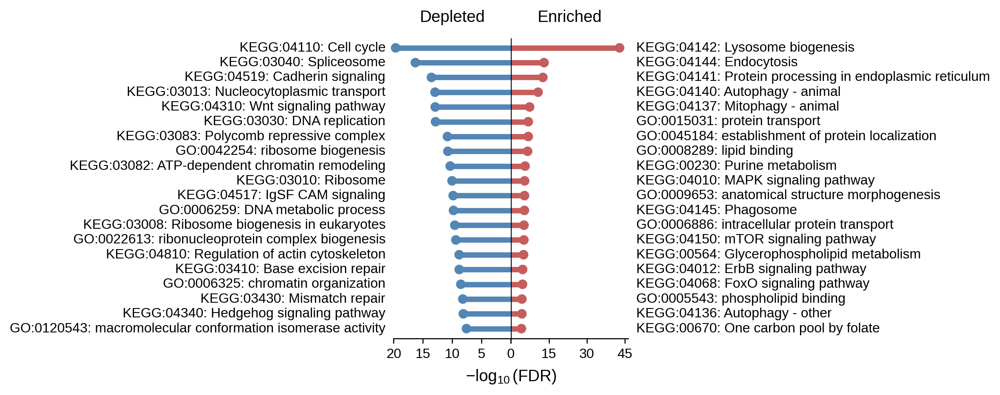

In [ ]:
plt.rcParams.update({
    "font.size": 10,         # default
    "axes.titlesize": 10,    # panel titles
    "xtick.labelsize": 8,   # x-axis tick labels
    "figure.labelsize": 8,  # shared "Fold enrichment" label
})

plt.rcParams.update({
    "font.family": "Liberation Sans",
    "mathtext.fontset": "custom",
    "mathtext.rm": "Liberation Sans",
    "mathtext.it": "Liberation Sans:italic",
    "mathtext.bf": "Liberation Sans:bold",
})

fig, axes, plot_tables = plot_term_enrichment(
    enriched=ysl_enriched_terms,
    depleted=ysl_depleted_terms,
    databases=None,       # None for all databases
    top_n=20,
    fdr_threshold=None,
    min_overlap=None,
    layout="opposing",
    independent_x=True,    # True to fit each side independently
    enriched_xlim=None,     # maximum in -log10(FDR) units
    depleted_xlim=20,
    normalize_y=True,
    label_terms=True,
    enriched_color="#C65D5D",
    depleted_color="#5386B5",
    dot_size=50,
    line_width=4,
    title_fontsize=12,
    label_fontsize=12,
    tick_fontsize=10,
    term_fontsize=10,
    figsize=(6, 4),
)

plt.show()
fig.savefig(base_path+'figs/'+'YSL_GOKEGG_plot.pdf', dpi=600, bbox_inches="tight")
fig.savefig(base_path+'figs/'+'YSL_GOKEGG_plot.png', dpi=600, bbox_inches="tight")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scanpy as sc
from scipy import sparse
from adjustText import adjust_text

def plot_ma(
    adata,
    group,
    groupby=None,
    reference=None,
    key="rank_genes_groups",
    layer=None,
    use_raw=False,
    input_log1p=True,
    log_base=None,
    fdr_threshold=0.05,
    log2fc_threshold=1,
    enriched_color="#C65D5D",
    depleted_color="#5386B5",
    nonsignificant_color="#D0D0D0",
    dot_size=8,
    alpha=0.6,
    show_thresholds=True,
    show_grid=False,
    show_counts=True,
    counts_fontsize=11,
    counts_x=1.03,
    label_genes=None,
    highlight_size=35,
    highlight_edgewidth=0.8,
    label_line_color="#555555",
    label_line_width=0.7,
    adjust_text_kwargs={"force_static": (0.3, 0.5),  # push labels away from points
                        "force_pull": (0, 0),
                        "expand": (1.3, 1.5),       # extra clearance around labels
                        "min_arrow_len": 0},        # draw connecting lines},
    title=None,
    title_fontsize=12,
    label_fontsize=10,
    tick_fontsize=10,
    gene_fontsize=8,
    xlim=None,
    ylim=None,
    figsize=(8, 5),
):
    """
    MA-style plot using stored Scanpy DE results.

    X: log10(1 + mean normalized expression), using the equally
       weighted average of the group and reference means.
    Y: stored log2 fold change.

    Counts include all plottable genes, even outside explicit axis limits.
    'Unchanged' means not passing both DEG thresholds.
    Selected genes are labeled only if inside the displayed limits.

    Returns
    -------
    fig, ax, table
        DE results plus expression means, plotting coordinates,
        Status, and Plottable.
    """
    if not 0 < fdr_threshold <= 1:
        raise ValueError("fdr_threshold must be > 0 and <= 1.")
    if not np.isfinite(log2fc_threshold) or log2fc_threshold < 0:
        raise ValueError("log2fc_threshold must be finite and >= 0.")
    if layer is not None and use_raw:
        raise ValueError("Choose either layer or use_raw.")
    if log_base is not None and (
        not np.isfinite(log_base) or log_base <= 1
    ):
        raise ValueError("log_base must be > 1 or None.")

    params = adata.uns[key].get("params", {})
    stored_groupby = params.get("groupby")
    stored_reference = params.get("reference")

    groupby = stored_groupby if groupby is None else groupby
    reference = stored_reference if reference is None else reference

    if groupby is None or reference is None:
        raise ValueError("Specify groupby and reference.")

    if stored_groupby is not None and groupby != stored_groupby:
        raise ValueError("groupby must match the stored DE comparison.")
    if stored_reference is not None and reference != stored_reference:
        raise ValueError("reference must match the stored DE comparison.")

    labels = adata.obs[groupby]
    group_mask = labels.eq(group).fillna(False).to_numpy(dtype=bool)

    if reference == "rest":
        reference_mask = labels.notna().to_numpy() & ~group_mask
    else:
        reference_mask = (
            labels.eq(reference).fillna(False).to_numpy(dtype=bool)
        )

    if not group_mask.any() or not reference_mask.any():
        raise ValueError("Group or reference contains no observations.")
    if np.any(group_mask & reference_mask):
        raise ValueError("Group and reference must not overlap.")

    if use_raw:
        if adata.raw is None:
            raise ValueError("adata.raw is unavailable.")
        matrix = adata.raw.X
        gene_names = adata.raw.var_names
    else:
        matrix = adata.X if layer is None else adata.layers[layer]
        gene_names = adata.var_names

    if not gene_names.is_unique:
        raise ValueError("Expression-matrix gene names must be unique.")

    table = sc.get.rank_genes_groups_df(
        adata, group=group, key=key
    ).copy()

    missing = {"names", "logfoldchanges", "pvals_adj"} - set(table.columns)
    if missing:
        raise ValueError(f"Missing DE columns: {sorted(missing)}")

    positions = gene_names.get_indexer(table["names"])
    present = positions >= 0
    if not present.any():
        raise ValueError("No DE genes match the expression matrix.")

    selected_positions = positions[present]

    def mean_linear(mask):
        values = matrix[mask, :][:, selected_positions]
        values = values.astype(np.float64, copy=True)
        data = values.data if sparse.issparse(values) else values

        if not np.isfinite(data).all() or (data < 0).any():
            raise ValueError(
                "Use finite, nonnegative normalized expression, "
                "not scaled/z-scored data."
            )

        if input_log1p:
            factor = 1.0 if log_base is None else np.log(log_base)
            with np.errstate(over="ignore"):
                transformed = np.expm1(data * factor)

            if not np.isfinite(transformed).all():
                raise ValueError(
                    "Log inversion overflowed. Check input_log1p "
                    "and the selected matrix."
                )

            if sparse.issparse(values):
                values.data = transformed
            else:
                values = transformed

        return np.asarray(values.mean(axis=0)).ravel()

    table["MeanGroup"] = np.nan
    table["MeanReference"] = np.nan
    table.loc[present, "MeanGroup"] = mean_linear(group_mask)
    table.loc[present, "MeanReference"] = mean_linear(reference_mask)
    table["MeanExpression"] = (
        table["MeanGroup"] + table["MeanReference"]
    ) / 2
    table["Log10MeanExpression"] = np.log10(1 + table["MeanExpression"])

    fc = table["logfoldchanges"].to_numpy(dtype=float)
    fdr = table["pvals_adj"].to_numpy(dtype=float)
    means = table["MeanExpression"].to_numpy(dtype=float)

    valid = (
        present
        & np.isfinite(fc)
        & np.isfinite(fdr)
        & (fdr >= 0)
        & (fdr <= 1)
        & np.isfinite(means)
        & (means > 0)
    )
    if not valid.any():
        raise ValueError("No genes have valid values for plotting.")

    table["Plottable"] = valid
    table["Status"] = "Unchanged"
    table.loc[~valid, "Status"] = "Not plotted"
    table.loc[
        valid & (fdr < fdr_threshold) & (fc > log2fc_threshold),
        "Status",
    ] = "Upregulated"
    table.loc[
        valid & (fdr < fdr_threshold) & (fc < -log2fc_threshold),
        "Status",
    ] = "Downregulated"

    colors = {
        "Unchanged": nonsignificant_color,
        "Downregulated": depleted_color,
        "Upregulated": enriched_color,
    }

    fig, ax = plt.subplots(figsize=figsize)
    ax.grid(False, which="both", axis="both")
    if show_grid:
        ax.set_axisbelow(True)
        ax.grid(True, color="#E5E5E5", linewidth=0.6)

    for status, color in colors.items():
        subset = table.loc[valid & table["Status"].eq(status)]
        ax.scatter(
            subset["Log10MeanExpression"],
            subset["logfoldchanges"],
            s=dot_size,
            color=color,
            alpha=alpha,
            edgecolors="none",
            zorder=2 if status == "Unchanged" else 3,
        )

    ax.axhline(0, color="#888888", linewidth=0.8, zorder=1)
    if show_thresholds and log2fc_threshold > 0:
        for cutoff in [-log2fc_threshold, log2fc_threshold]:
            ax.axhline(
                cutoff, color="#888888",
                linestyle="--", linewidth=0.8, zorder=1,
            )

    ax.set_xlim(left=0)
    if xlim is not None:
        ax.set_xlim(*xlim)
    if ylim is not None:
        ax.set_ylim(*ylim)

    ax.set_title(
        str(group) if title is None else title,
        fontsize=title_fontsize, pad=10,
    )
    ax.set_xlabel(
        r"$\log_{10}(1 + \mathrm{mean\ normalized\ expression})$",
        fontsize=label_fontsize,
    )
    ax.set_ylabel(
        r"$\log_{2}(\mathrm{fold\ change})$",
        fontsize=label_fontsize,
    )
    ax.tick_params(axis="both", labelsize=tick_fontsize)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    # Reserve space for counts outside the right edge.
    fig.tight_layout(rect=(0, 0, 0.77 if show_counts else 1, 1))

    if show_counts:
        counts = table.loc[valid, "Status"].value_counts()
        for status, ypos, color in [
            ("Upregulated", 0.95, enriched_color),
            ("Downregulated", 0.83, depleted_color),
            ("Unchanged", 0.71, "#666666"),
        ]:
            ax.text(
                counts_x, ypos,
                f"{status}\nn = {counts.get(status, 0):,}",
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=counts_fontsize,
                color=color,
                clip_on=False,
            )

    if label_genes is not None:
        if isinstance(label_genes, str):
            label_genes = [label_genes]

        xmin, xmax = ax.get_xlim()
        ymin, ymax = ax.get_ylim()
        visible = (
            table["Plottable"]
            & table["Log10MeanExpression"].between(xmin, xmax)
            & table["logfoldchanges"].between(ymin, ymax)
        )
        selected = table.loc[
            visible & table["names"].isin(label_genes)
        ]

        if not selected.empty:
            xs = selected["Log10MeanExpression"].to_numpy()
            ys = selected["logfoldchanges"].to_numpy()

            # Preserve status color and add a black outline.
            ax.scatter(
                xs, ys,
                s=highlight_size,
                c=selected["Status"].map(colors).tolist(),
                edgecolors="black",
                linewidths=highlight_edgewidth,
                alpha=1,
                zorder=5,
            )

            # Initial label offset in display pixels
            offset_px = 50

            point_pixels = ax.transData.transform(
                np.column_stack([xs, ys])
            )
            point_pixels[:, 1] += offset_px
            label_positions = ax.transData.inverted().transform(
                point_pixels
            )

            texts = [
                ax.text(
                    x, y, str(name),
                    fontsize=gene_fontsize,
                    color="black",
                    zorder=6,
                )
                for (x, y), name in zip(
                    label_positions, selected["names"]
                )
            ]

            options = {
                "expand": (1.15, 1.3),
                "force_text": (0.2, 0.3),
                "min_arrow_len": 0,
                "time_lim": 2,
                "ensure_inside_axes": True,
                "arrowprops": {
                    "arrowstyle": "-",
                    "color": label_line_color,
                    "lw": label_line_width,
                    "shrinkA": 2,
                    "shrinkB": 3,
                    "zorder": 4,
                },
            }
            if adjust_text_kwargs:
                options.update(adjust_text_kwargs)

            fig.canvas.draw()
            background = table.loc[visible]

            adjust_text(
                texts,
                x=background["Log10MeanExpression"].to_numpy(),
                y=background["logfoldchanges"].to_numpy(),
                target_x=xs,
                target_y=ys,
                ax=ax,
                **options,
            )

    return fig, ax, table

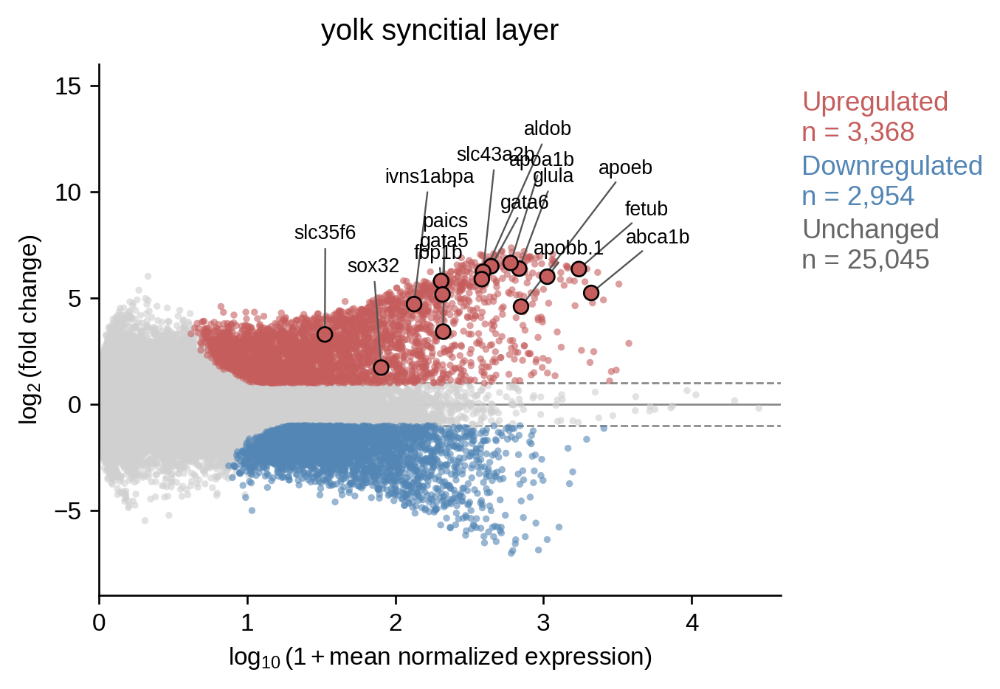

In [ ]:
fig, ax, ma_table = plot_ma(
    adata,
    group="yolk syncitial layer",  # exact stored group name
    # groupby and reference are inferred from the DE results
    use_raw=False,
    layer='tpm',                  # default uses adata.X
    input_log1p=True,             # assumes log1p
    fdr_threshold=0.05,
    log2fc_threshold=1,
    enriched_color="#C65D5D",
    depleted_color="#5386B5",
    show_grid=False,
    ylim=(-9, 16),
    xlim=(0,4.6),
    figsize=(6, 4),
    label_genes=['glula','aldob','fbp1b','apoeb','apobb.1','gata5','gata6',
                 'abca1b','ivns1abpa','paics','slc35f6','slc43a2b','sox32',
                 'fetub','apoa1b'],

)

plt.show()
fig.savefig(base_path+'figs/'+'YSL_maplot.pdf', dpi=600, bbox_inches="tight")
fig.savefig(base_path+'figs/'+'YSL_maplot.png', dpi=600, bbox_inches="tight")

## Cell Cycle Scoring

In [ ]:
import scanpy as sc
from gprofiler import GProfiler

s_human = ['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6',
           'CDCA7','DTL','PRIM1','UHRF1','MLF1IP','HELLS','RFC2','RPA2','NASP',
           'RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2',
           'RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2',
           'USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_human = ['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2',
             'NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2',
             'CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1',
             'KIF20B','HJURP','CDCA3','HN1','CDC20','TTK','CDC25C','KIF2C','RANGAP1',
             'NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1',
             'ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']

gp = GProfiler(return_dataframe=True)

def to_zebrafish(human_genes, var_names, id_type='symbol'):
    """Map human symbols -> zebrafish orthologs, keep only those present in adata."""
    orth = gp.orth(query=human_genes, organism='hsapiens', target='drerio')
    orth = orth[orth['ortholog_ensg'] != 'N/A']          # drop unmapped
    col = 'name' if id_type == 'symbol' else 'ortholog_ensg'
    mapped = orth[col].str.lower() if id_type == 'symbol' else orth[col]
    present = sorted(set(mapped) & set(v.lower() for v in var_names)) if id_type=='symbol' \
              else sorted(set(mapped) & set(var_names))
    return present

# id_type='symbol' if var_names are gene symbols; 'ensembl' if ENSDARG IDs
vn = list(adata.var_names)
s_zf   = to_zebrafish(s_human,   vn, id_type='symbol')
g2m_zf = to_zebrafish(g2m_human, vn, id_type='symbol')

print(f"S: {len(s_zf)}/{len(s_human)} mapped | G2M: {len(g2m_zf)}/{len(g2m_human)} mapped")

S: 38/43 mapped | G2M: 44/54 mapped


In [ ]:
s_zf[0:5]
g2m_zf[0:5]

['anln', 'anp32e', 'aurka', 'aurkb', 'bub1']

In [ ]:
s_genes_zf = [
    'mcm5', 'pcna', 'tyms', 'mcm7', 'mcm4', 'rrm1', 'ung1', 'gins2',
    'mcm6', 'cdca7', 'dtl', 'prim1', 'uhrf1', 'cenpu', 'gmnn', 'hells',
    'ccne2', 'cdc6', 'rfc2', 'polr1b', 'nasp', 'rad51ap1', 'wdr76',
    'slbp', 'ubr7', 'pold3', 'msh2', 'atad2', 'rad51', 'rrm2', 'cdc45',
    'exo1', 'tipin', 'dscc1', 'blm', 'casbap2', 'usp1', 'clspn',
    'pola1', 'chaf1b', 'mrpl36', 'e2f8'
]

g2m_genes_zf = [
    'cdk1', 'ube2c', 'birc5', 'top2a', 'tpx2', 'cks2', 'nuf2', 'mki67',
    'tacc3', 'cenpf', 'smc4', 'ckap4', 'kif11', 'cdca3', 'hmgb2',
    'ndc80', 'cks1b', 'tmpo', 'pimreg', 'ccnb2', 'ckap2l', 'ckap2',
    'aurkb', 'bub1', 'anp32e', 'tubb4b', 'gtse1', 'kif20b', 'hjurp',
    'jpt1', 'cdc20', 'ttk', 'cdc25c', 'kif2c', 'rangap1', 'ncapd2',
    'dlgap5', 'cdca8', 'cdca2', 'ect2', 'kif23', 'hmmr', 'aurka',
    'psrc1', 'anln', 'lbr', 'ckap5', 'cenpe', 'ctcf', 'nek2', 'g2e3',
    'gas2l3', 'cbx5', 'cenpa'
]

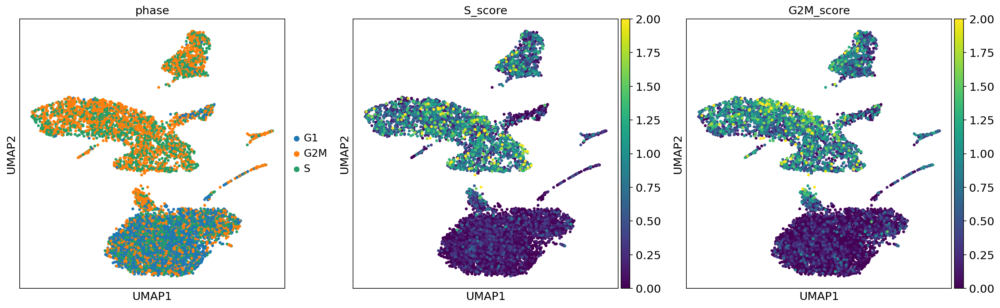

In [ ]:
# Must run on log1p-normalized data (adata.X or a layer), BEFORE scaling/regression.
sc.tl.score_genes_cell_cycle(adata, s_genes=s_zf, g2m_genes=g2m_zf, layer='tpm')

sc.set_figure_params(figsize=(6, 6), dpi=80)
sc.pl.umap(adata, color=['phase', 'S_score', 'G2M_score'], vmin=0, vmax=2, s=50)

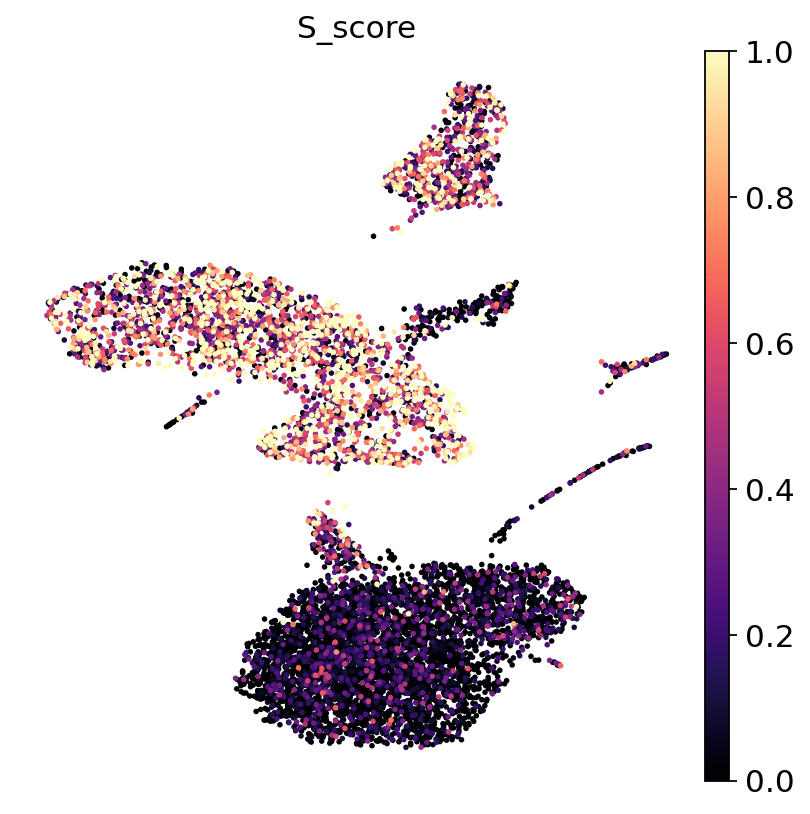

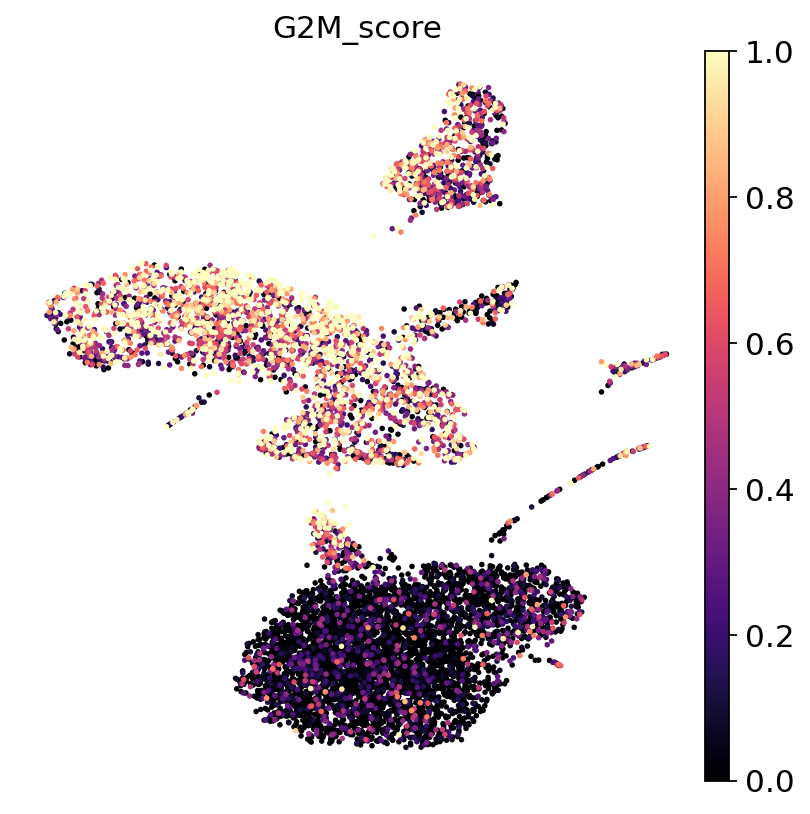

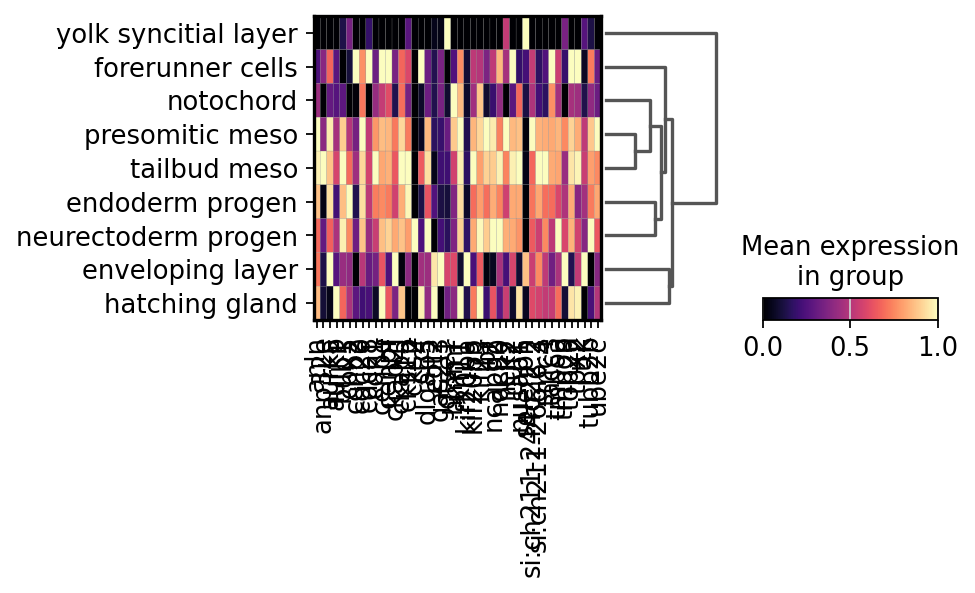

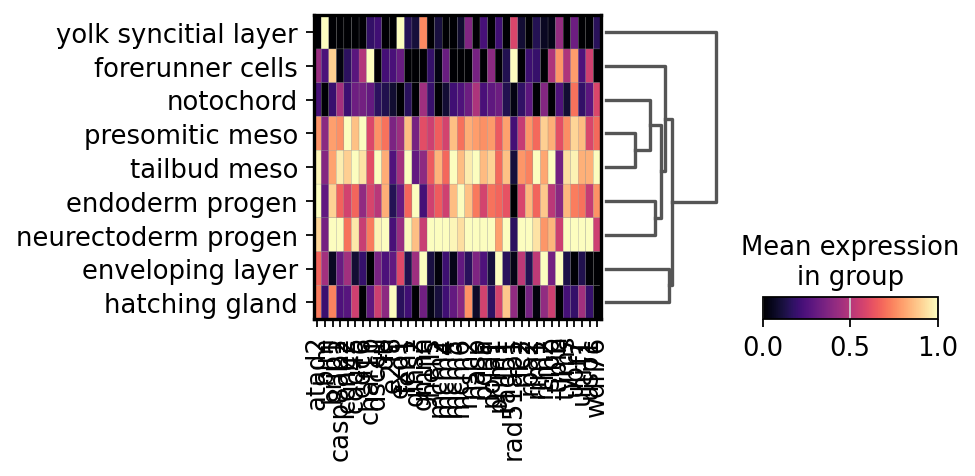

In [ ]:
f1 = sc.pl.umap(adata,
               color='S_score',
               cmap='magma',
               s=25, alpha=1,
               vmax=1, vmin=0,
               frameon=False,
               show=True,
               return_fig=True)

f2 = sc.pl.umap(adata,
               color='G2M_score',
               cmap='magma',
               s=25, alpha=1,
               vmax=1, vmin=0,
               frameon=False,
               show=True,
               return_fig=True)

f3 = sc.pl.matrixplot(adata,
                      var_names=g2m_zf,
                      groupby='ZMAP_CellType_mapped',
                      standard_scale='var', layer='tpm',
                      cmap='magma',
                      dendrogram=True,
                      swap_axes=False,
                      figsize=(5, 2.5))

f4 = sc.pl.matrixplot(adata,
                      var_names=s_zf,
                      groupby='ZMAP_CellType_mapped',
                      standard_scale='var', layer='tpm',
                      cmap='magma',
                      dendrogram=True,
                      swap_axes=False,
                      figsize=(5, 2.5))


f1.savefig(base_path+'figs/'+'YSL_cellcycle_scores_s.png', dpi=600, bbox_inches="tight")
f2.savefig(base_path+'figs/'+'YSL_cellcycle_scores_g2m.png', dpi=600, bbox_inches="tight")


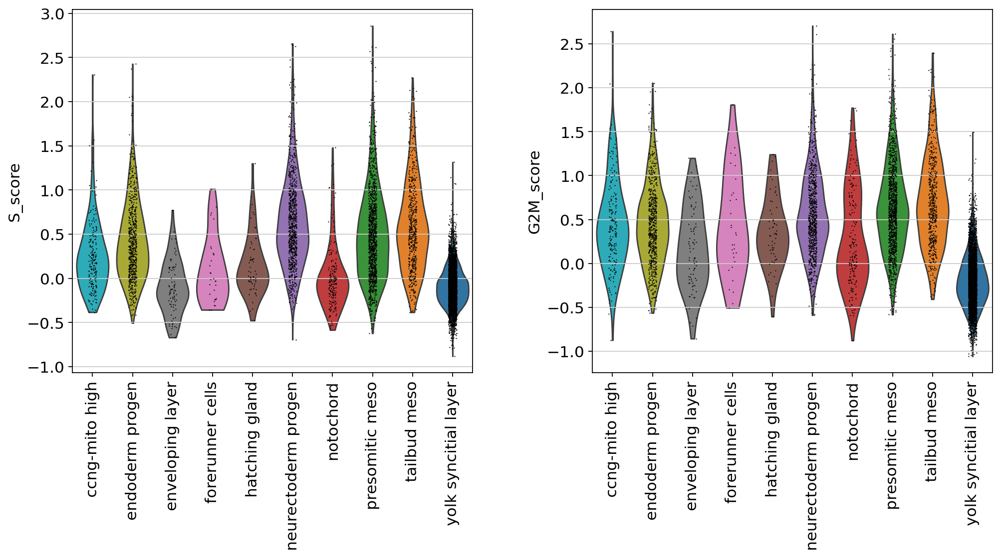

In [ ]:
sc.pl.violin(adata, ['S_score', 'G2M_score'], groupby='ZMAP_CellType_mapped_ccng', rotation=90)

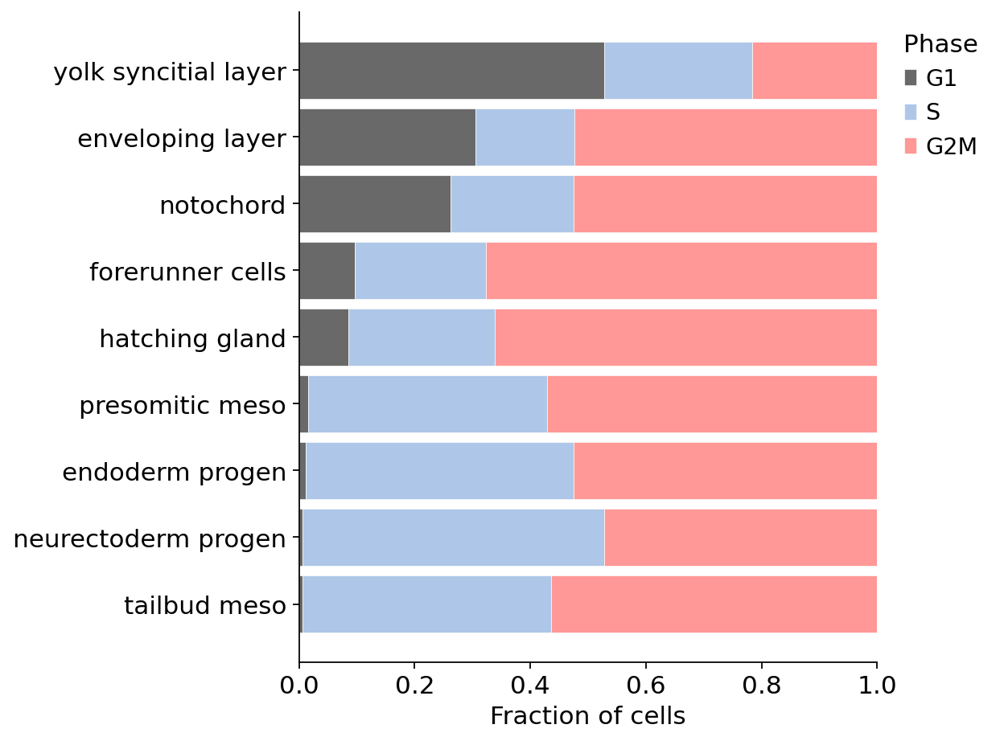

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def plot_phase_composition(
    adata,
    celltype_key,
    phase_key='phase',
    normalize=True,
    order_by='G2M',
    figsize=(8, 6),
    colors=None,
    ax=None,
):
    """
    Horizontal stacked barplot of cell-cycle phase composition across cell types.

    Parameters
    ----------
    adata
        AnnData object.

    celltype_key : str
        Column in adata.obs containing cell-type labels.

    phase_key : str, default='phase'
        Column in adata.obs containing cell-cycle phase labels.

    normalize : bool, default=True
        If True, plot fractions per cell type.
        If False, plot raw cell counts.

    order_by : {'G1', 'S', 'G2M', 'cycling', 'name', None}
        Order cell types by the selected phase fraction, descending.
        'cycling' orders by S + G2M.
        'name' orders alphabetically.
        None preserves the existing order.

    figsize : tuple, default=(6, 4)
        Figure size used when ax is not supplied.

    colors : dict or None
        Dictionary mapping G1, S, and G2M to colors.

    ax : matplotlib.axes.Axes or None
        Existing axis on which to draw.

    Returns
    -------
    ax
        Matplotlib axis.

    data
        DataFrame containing the plotted values.
    """

    phase_order = ['G1', 'S', 'G2M']

    if colors is None:
        tab20 = plt.get_cmap('tab20').colors
        colors = {
            'G1': 'dimgrey',
            'S': tab20[1],
            'G2M': tab20[7],
        }

    ct = adata.obs[celltype_key]

    ph = pd.Categorical(
        adata.obs[phase_key],
        categories=phase_order,
        ordered=True,
    )

    counts = pd.crosstab(ct, ph)
    counts = counts.reindex(columns=phase_order, fill_value=0)

    totals = counts.sum(axis=1)
    frac = counts.div(totals.replace(0, np.nan), axis=0).fillna(0)

    # Determine cell-type order
    if order_by == 'cycling':
        sort_key = frac[['S', 'G2M']].sum(axis=1)

    elif order_by in phase_order:
        sort_key = frac[order_by]

    else:
        sort_key = None

    if sort_key is not None:
        idx = sort_key.sort_values(ascending=False).index

    elif order_by == 'name':
        idx = sorted(counts.index.astype(str))

    else:
        idx = counts.index

    data = (frac if normalize else counts).loc[idx]

    if ax is None:
        _, ax = plt.subplots(figsize=figsize)

    y = np.arange(len(data))
    left = np.zeros(len(data))

    for phase in phase_order:
        values = data[phase].to_numpy()

        ax.barh(
            y,
            values,
            left=left,
            label=phase,
            color=colors[phase],
            height=0.85,
            edgecolor='white',
            linewidth=0.3,
        )

        left += values

    ax.set_xlabel(
        'Fraction of cells' if normalize else 'Number of cells'
    )
    ax.set_ylabel('')

    ax.set_yticks(y)
    ax.set_yticklabels(data.index)

    # Put the highest-ranked cell type at the top
    ax.invert_yaxis()

    if normalize:
        ax.set_xlim(0, 1)

    ax.legend(
        title='Phase',
        bbox_to_anchor=(1.01, 1),
        loc='upper left',
        frameon=False,
    )

    ax.grid(False)
    ax.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()

    return ax, data

ax, comp = plot_phase_composition(
    adata,
    celltype_key='ZMAP_CellType_mapped',
    order_by='G1')

ax.figure.savefig(base_path+'figs/'+'YSL_cellcycle_composition.pdf', dpi=600, bbox_inches="tight")

## Plot Gene-Overlay UMAPs

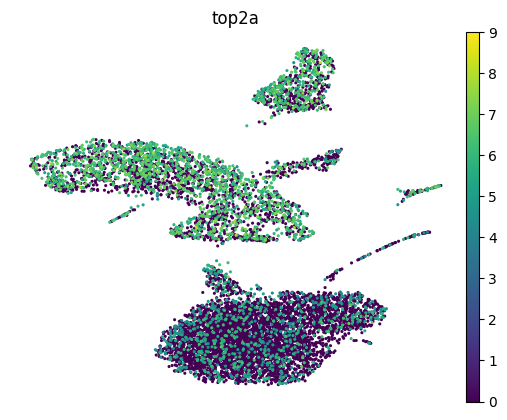

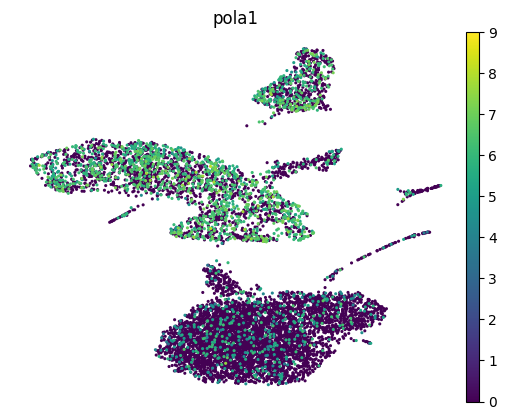

In [ ]:
gene_list = ['top2a','pola1']

for gene in gene_list:
    f = sc.pl.umap(adata, color=gene, s=20, frameon=False, vmax=9, layer='tpm', return_fig=True)
    #f.savefig('figs/'+gene+'.png', dpi=600, bbox_inches="tight")
    #f.savefig(base_path+'figs/'+gene+'.pdf', dpi=600, bbox_inches="tight")



In [ ]:
ysl_genes[0:20]

['katnal1',
 'bhmt',
 'mvp',
 'gatm',
 'a1cf',
 'plbd1',
 'anxa6',
 'hnf4b',
 'epas1a',
 'sema4gb',
 'ipcef1',
 'slc39a5',
 'zgc:85843',
 'iqgap2',
 'ctsba',
 'dmxl2',
 'slc25a22a',
 'trim16',
 'dpp7',
 'fbxl7']

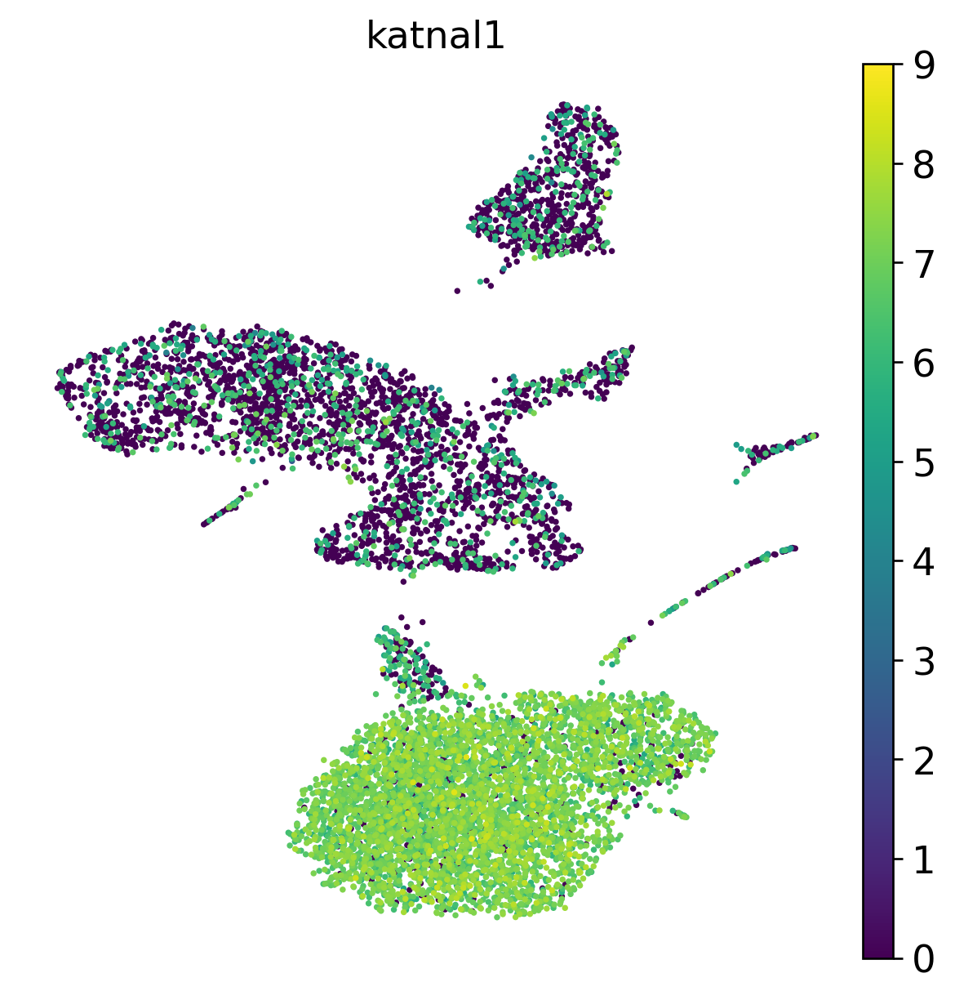

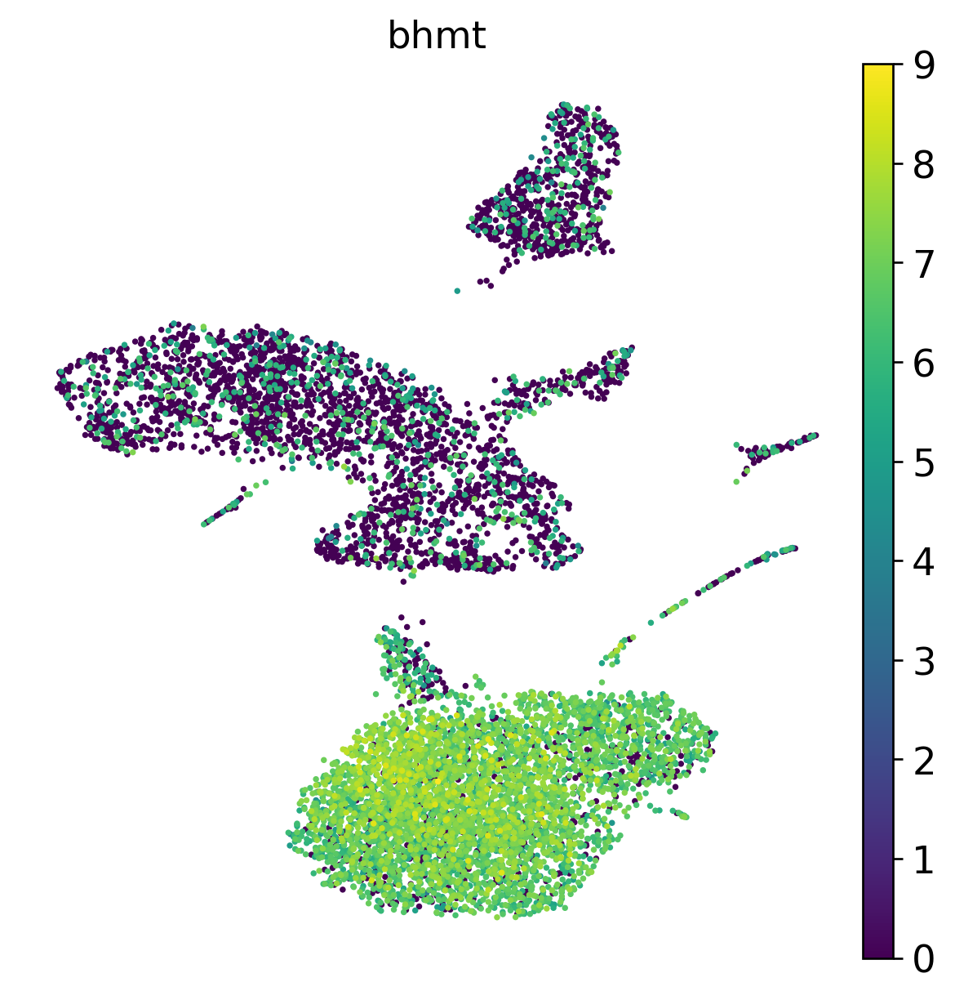

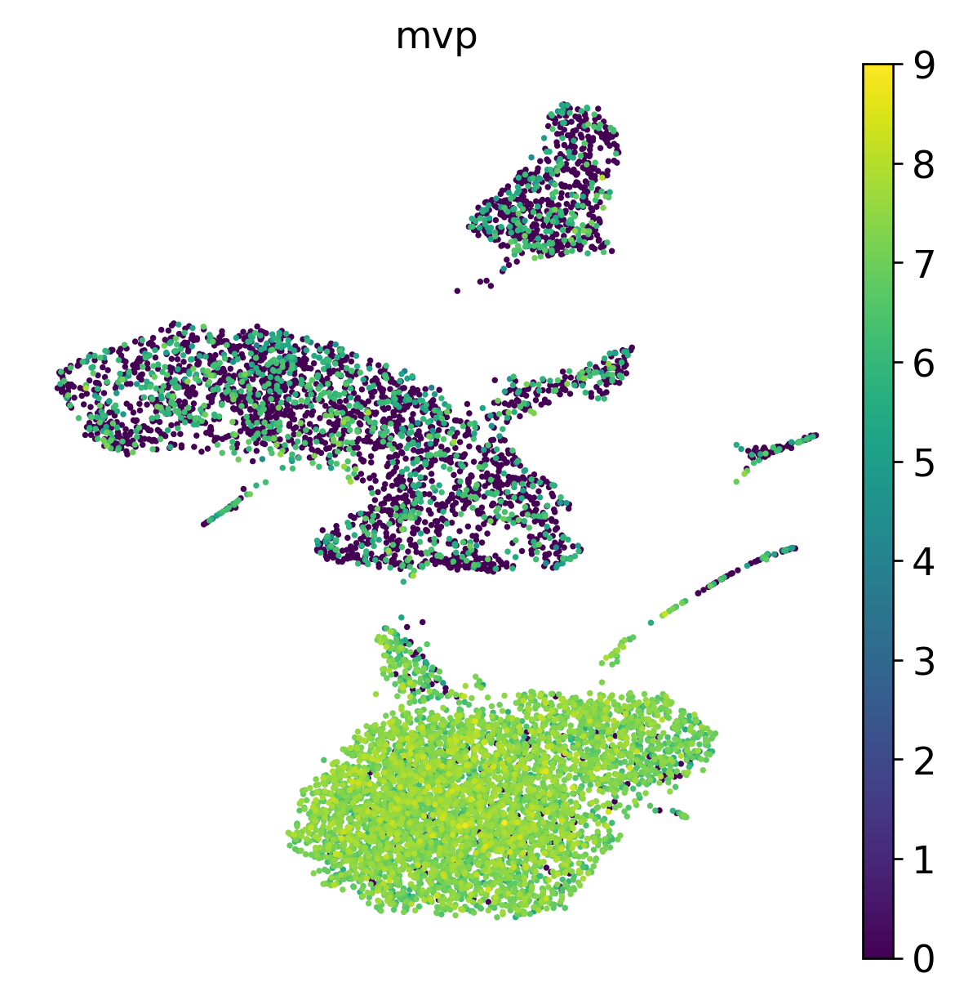

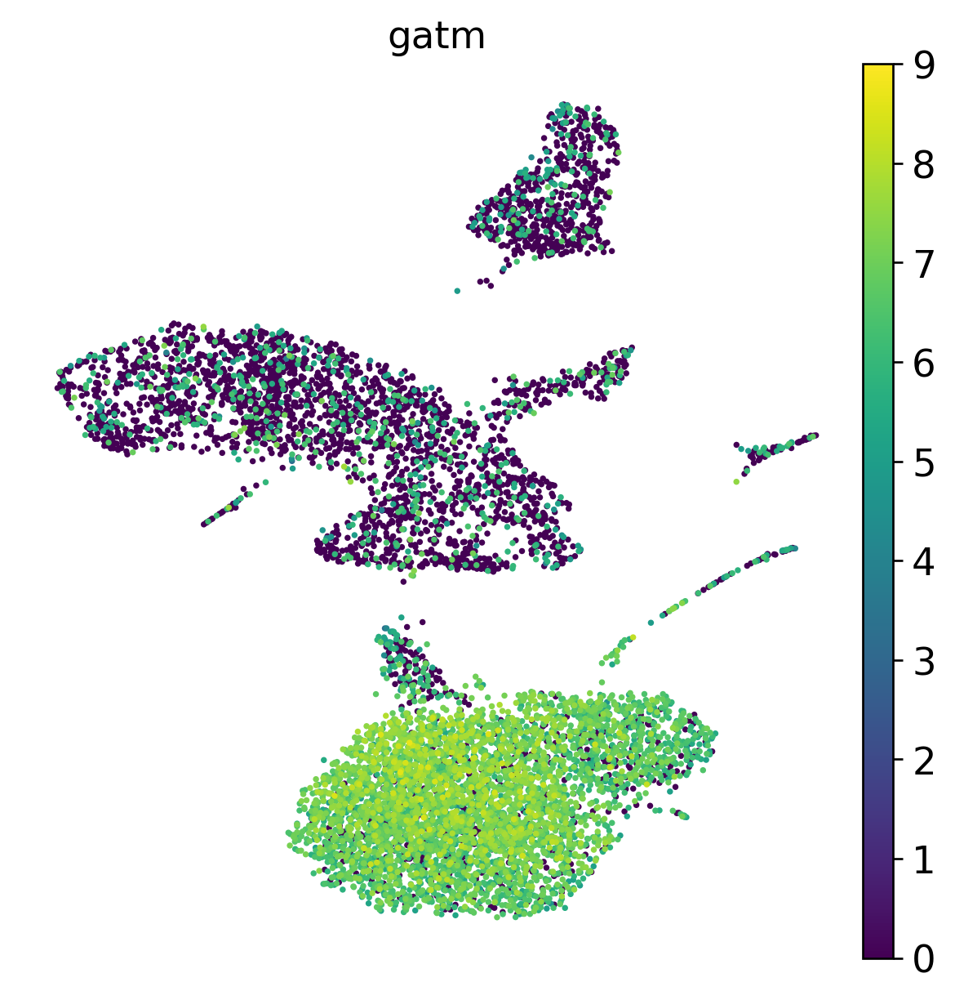

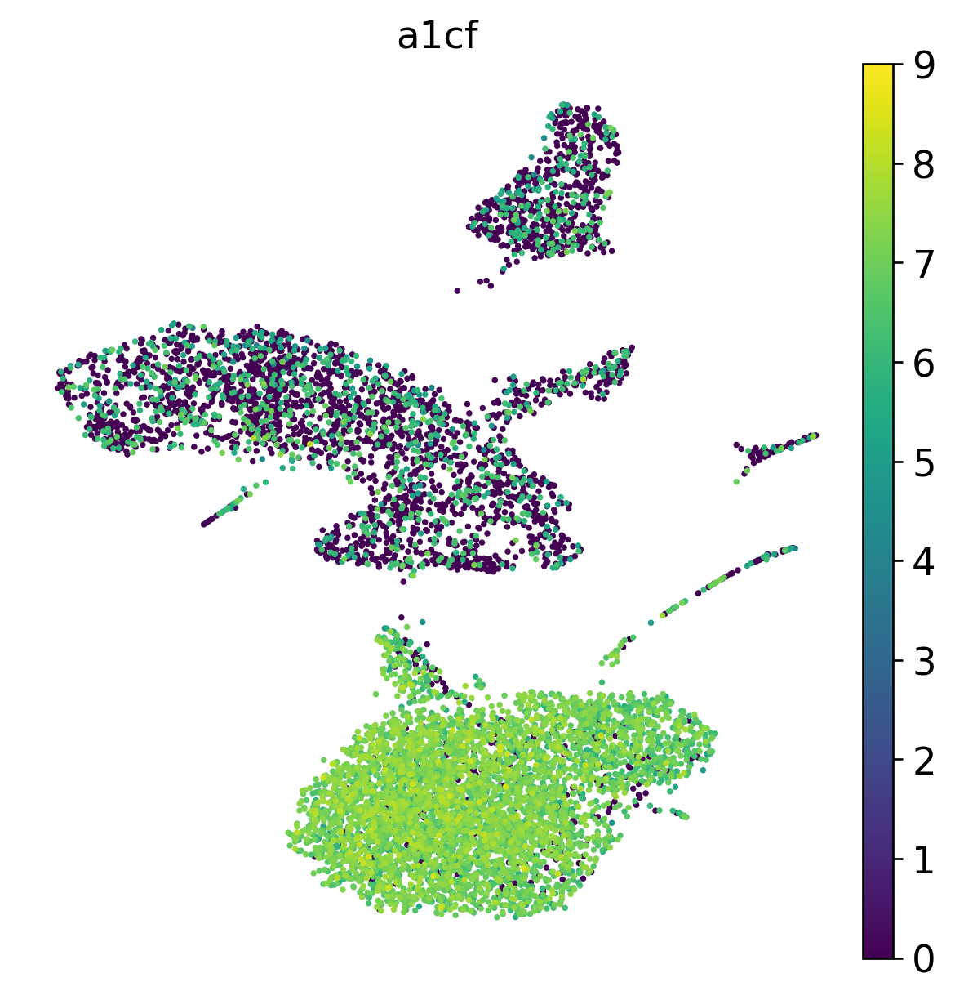

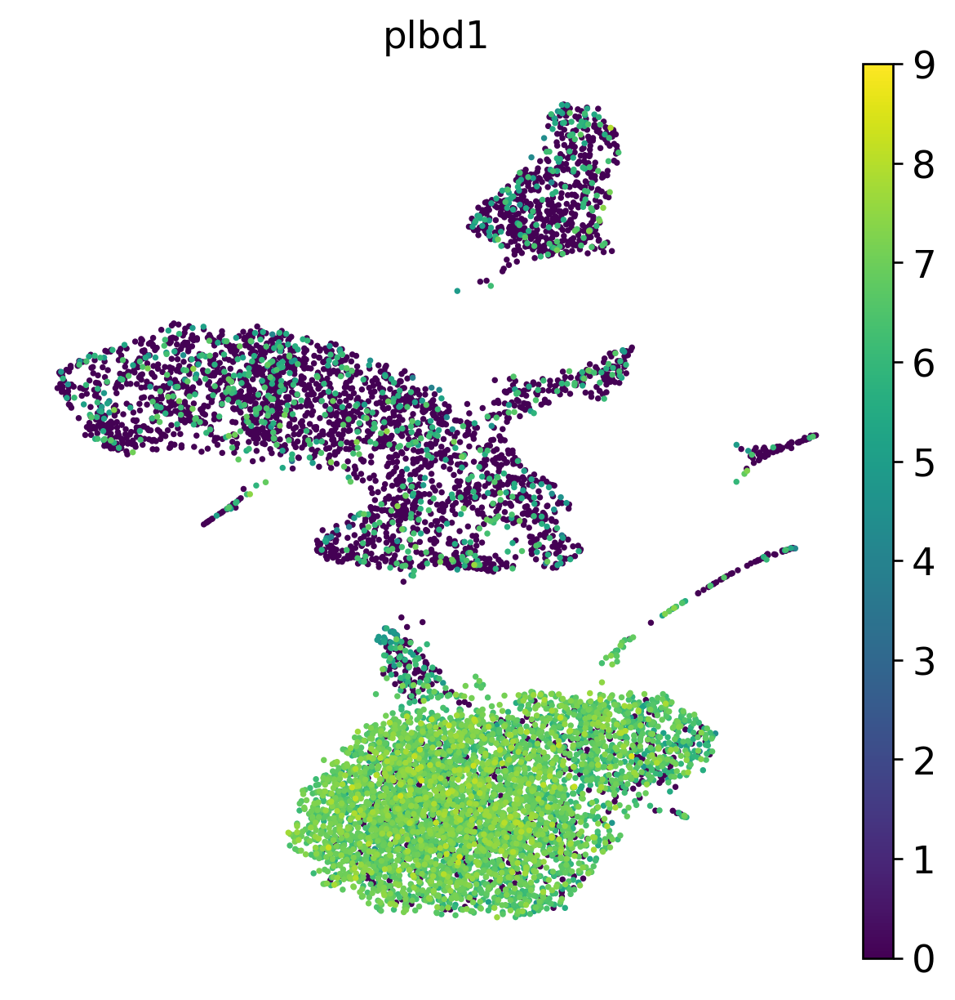

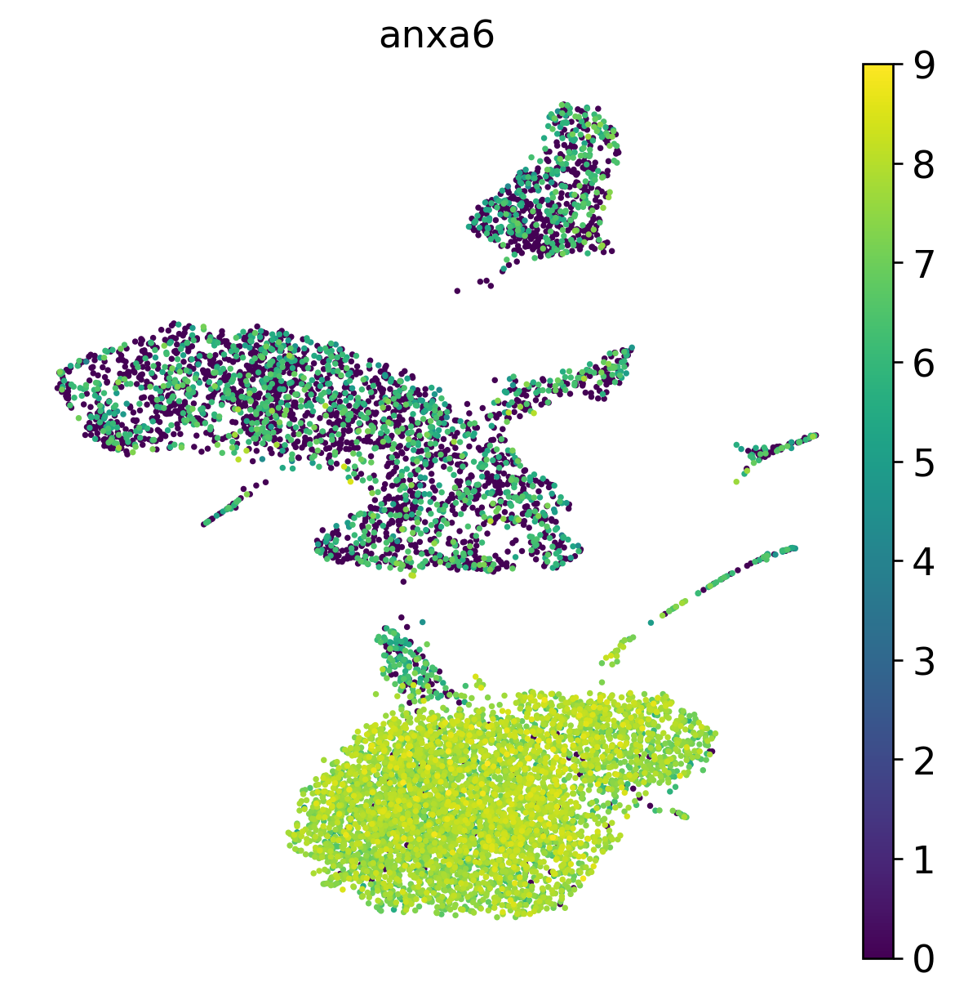

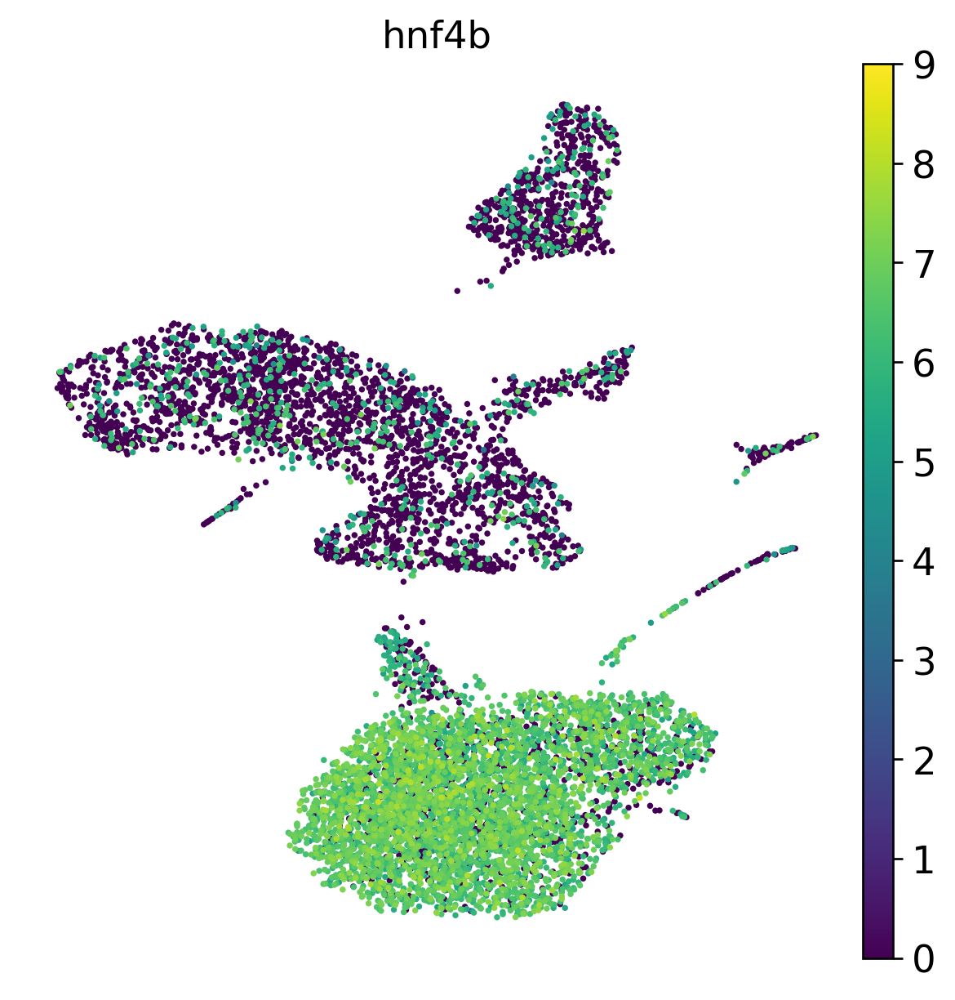

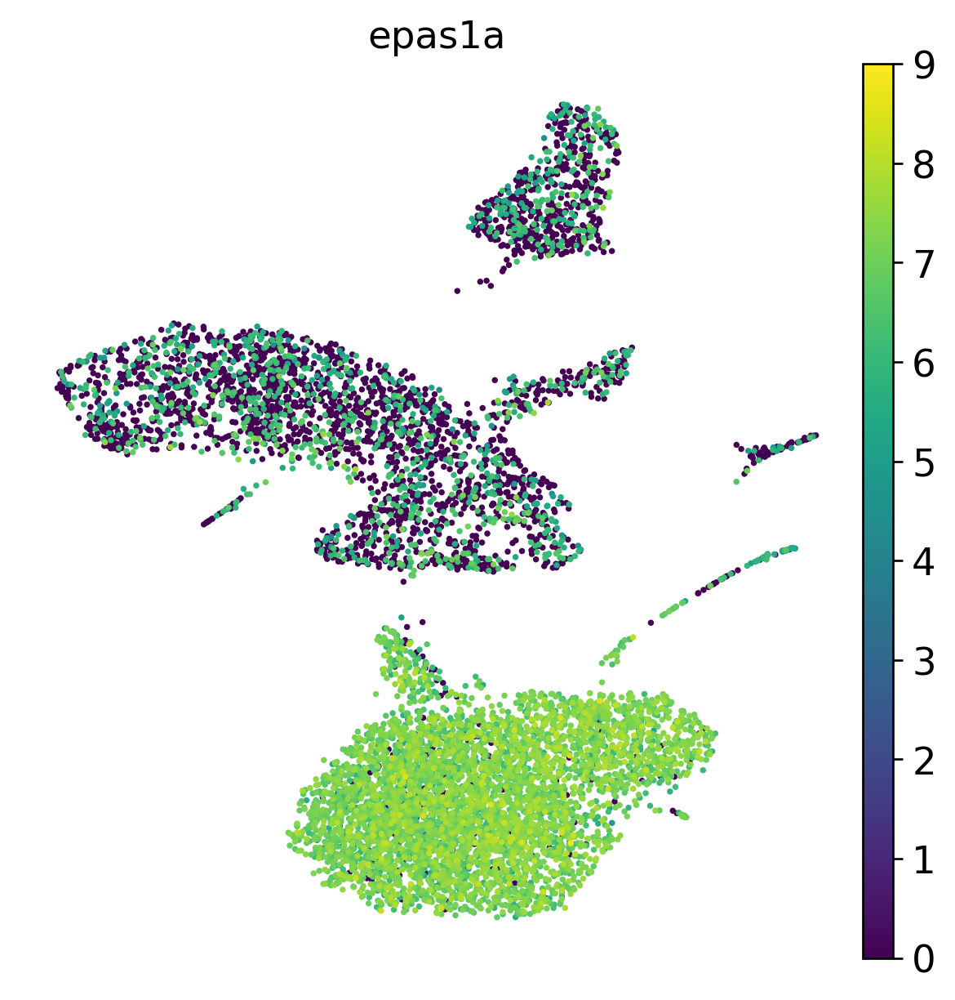

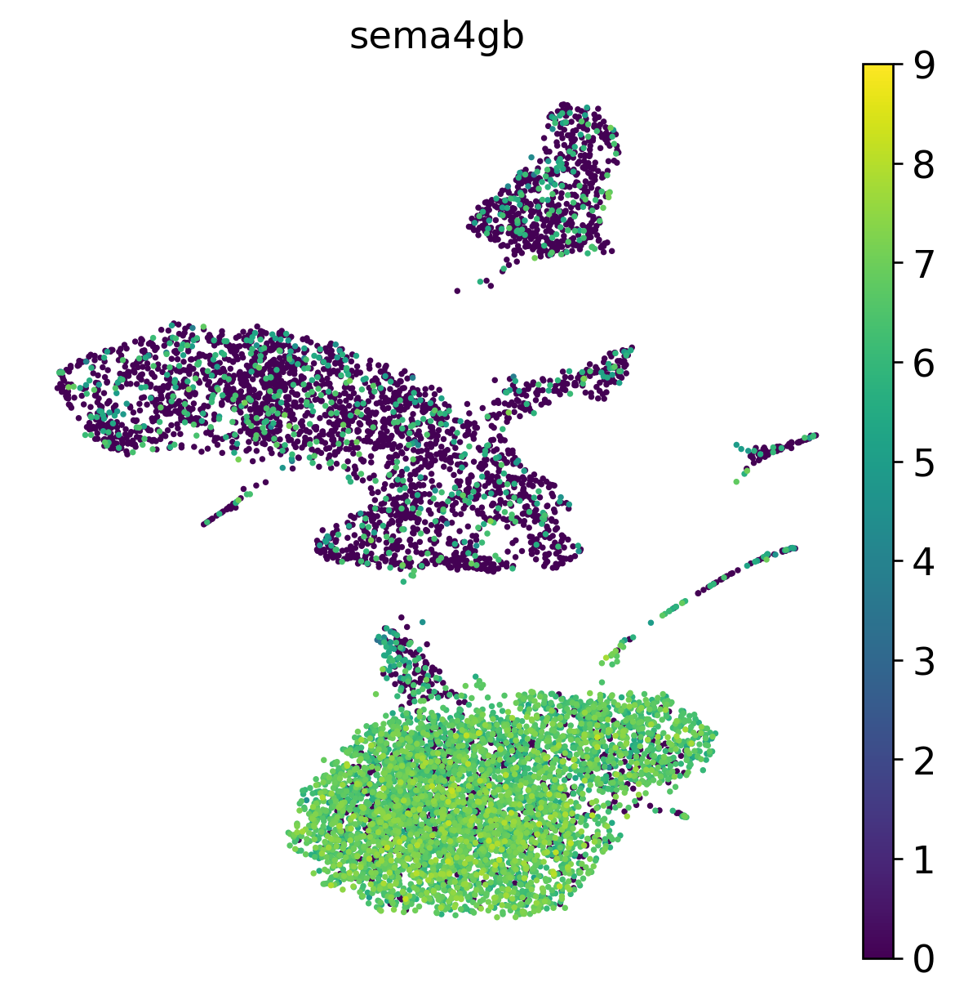

In [ ]:
sc.set_figure_params(figsize=(6, 6), dpi=120)

gene_list = ysl_genes[0:10]
#gene_list = pos_enrich_overlap['names'].head(10)
#gene_list = s_zf

for gene in gene_list:
    f = sc.pl.umap(adata, color=gene, s=20, frameon=False, vmax=9, layer='tpm', return_fig=True)
    #f.savefig('figs/'+gene+'.png', dpi=600, bbox_inches="tight")
    #f.savefig(base_path+'figs/'+gene+'.pdf', dpi=600, bbox_inches="tight")
    f.savefig(base_path+'figs/'+gene+'.png', dpi=600, bbox_inches="tight")



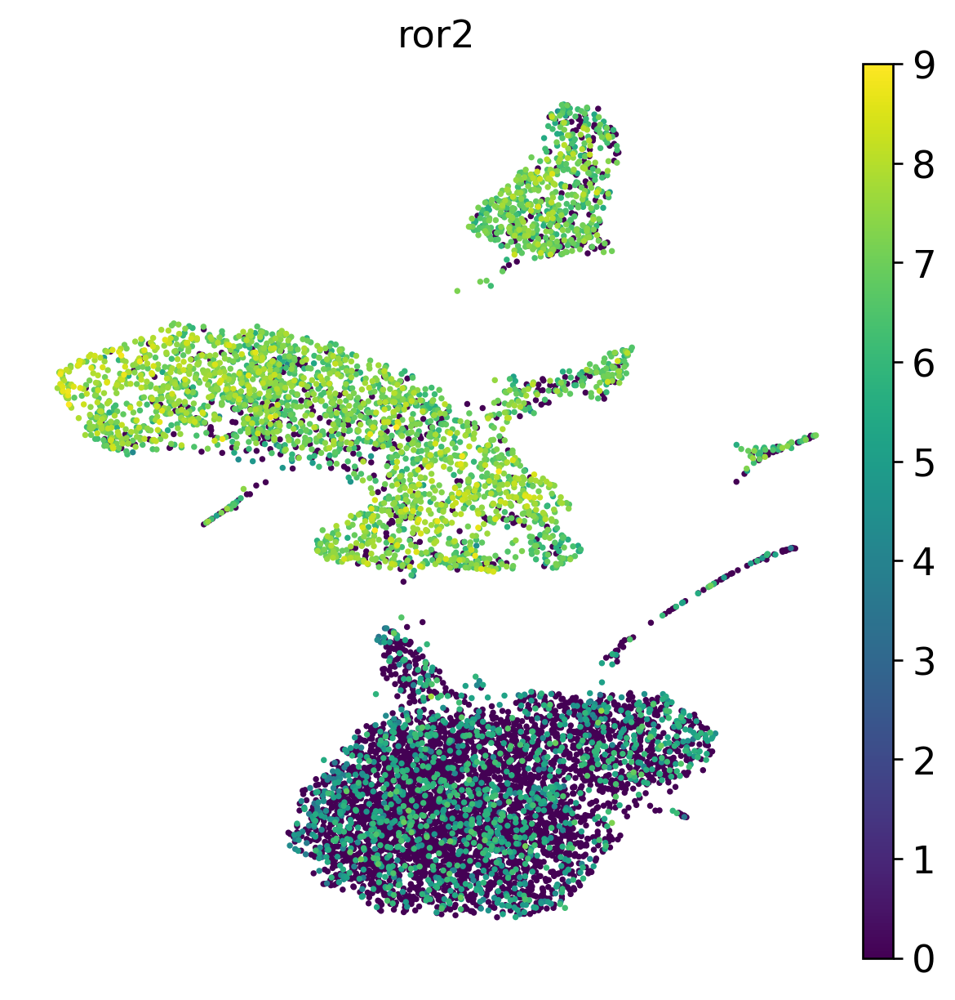

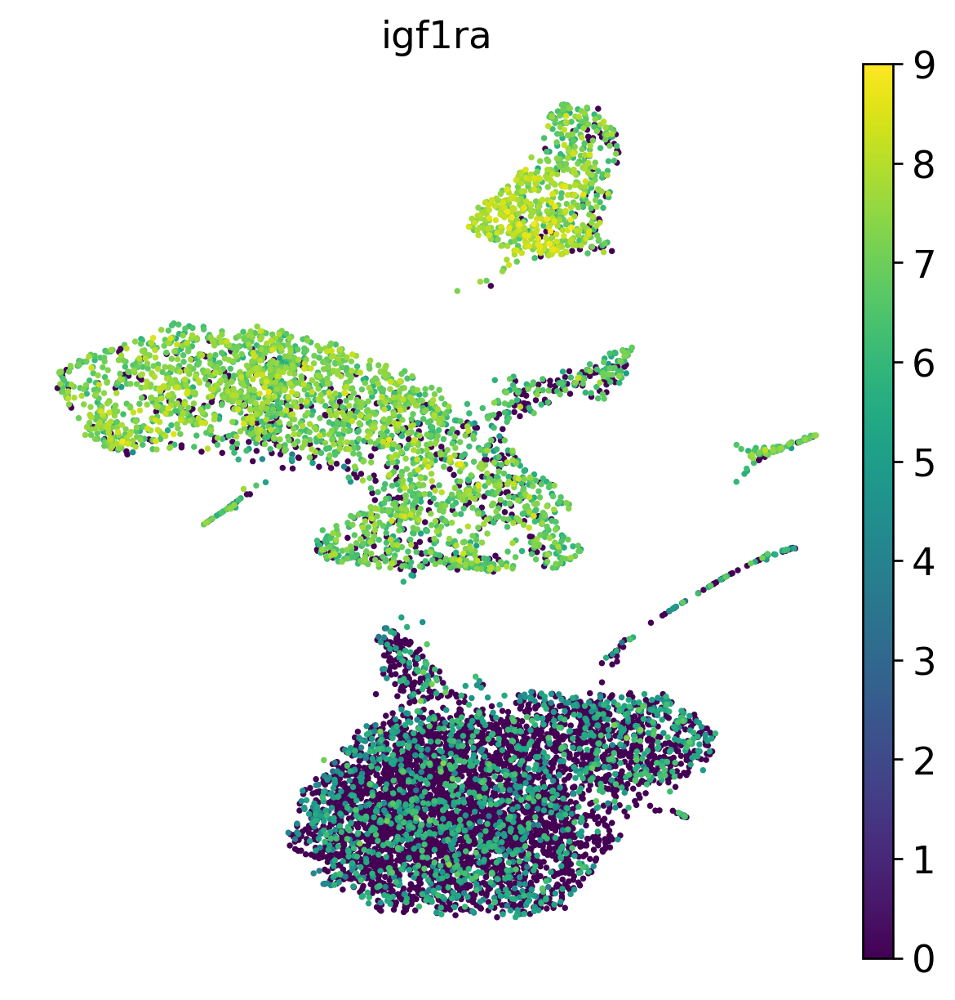

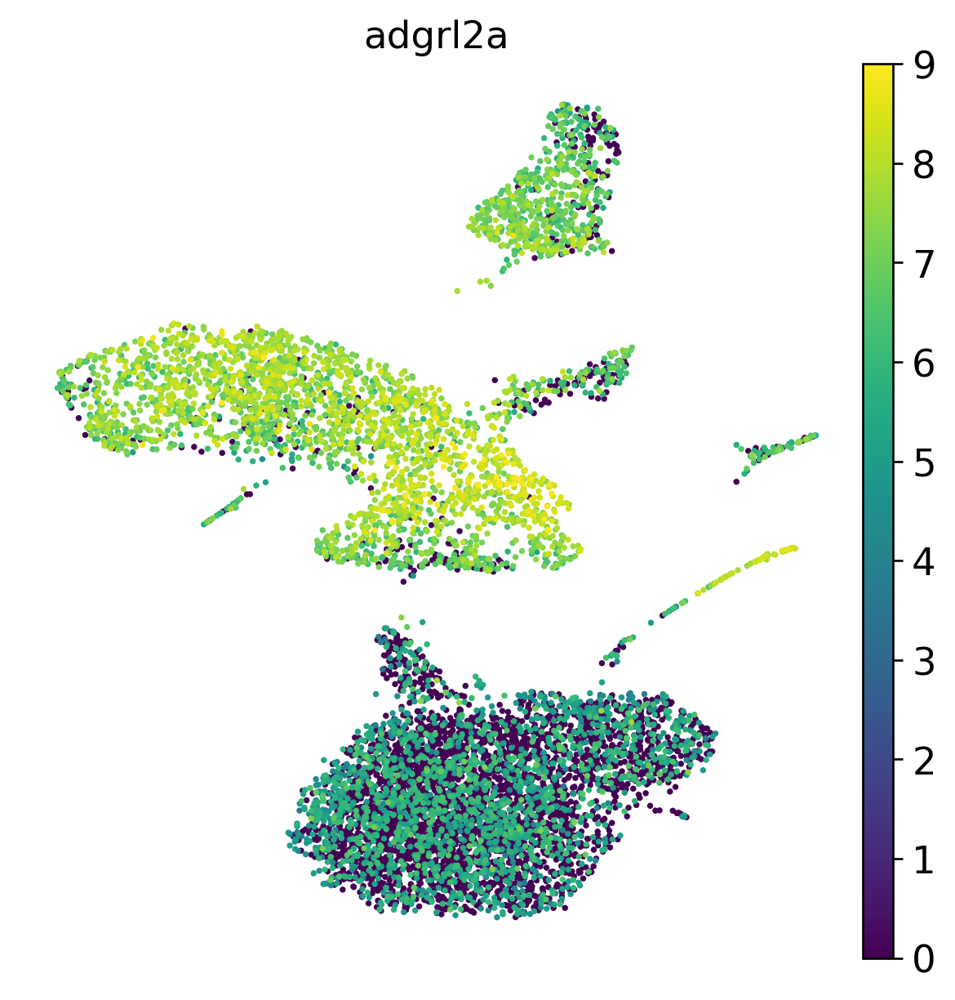

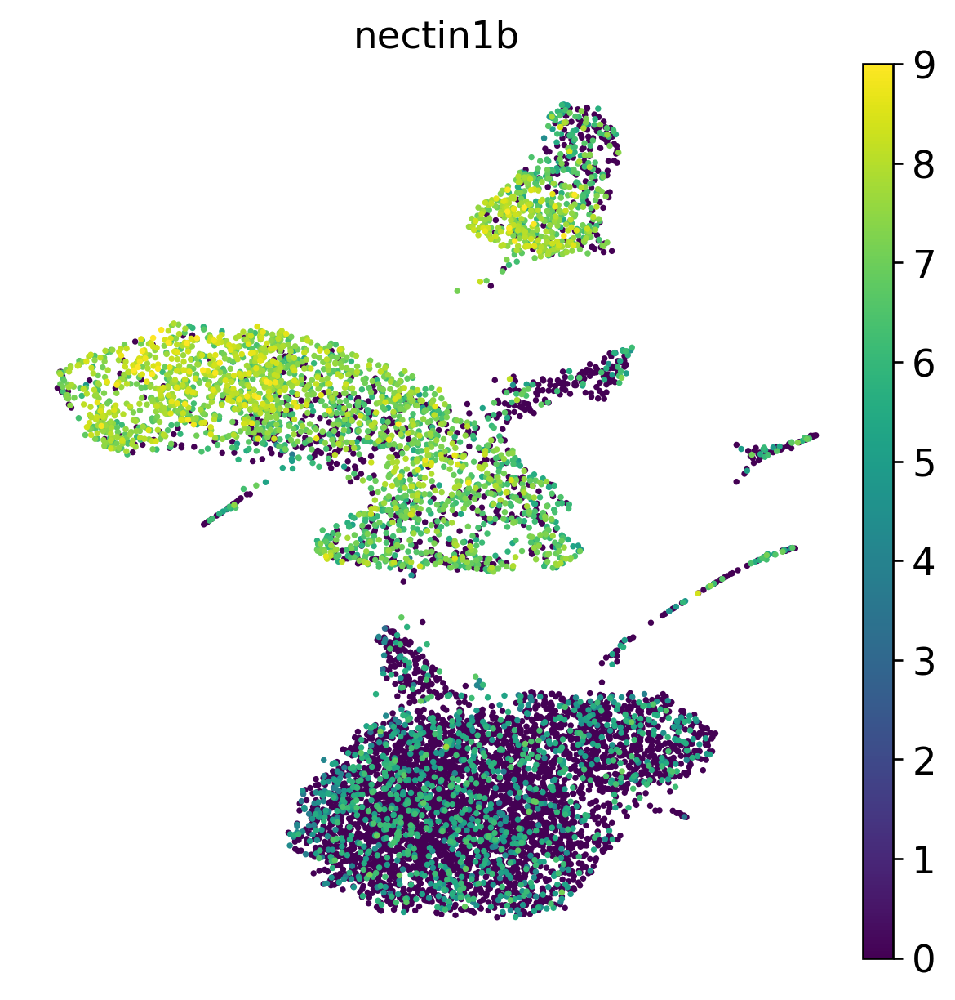

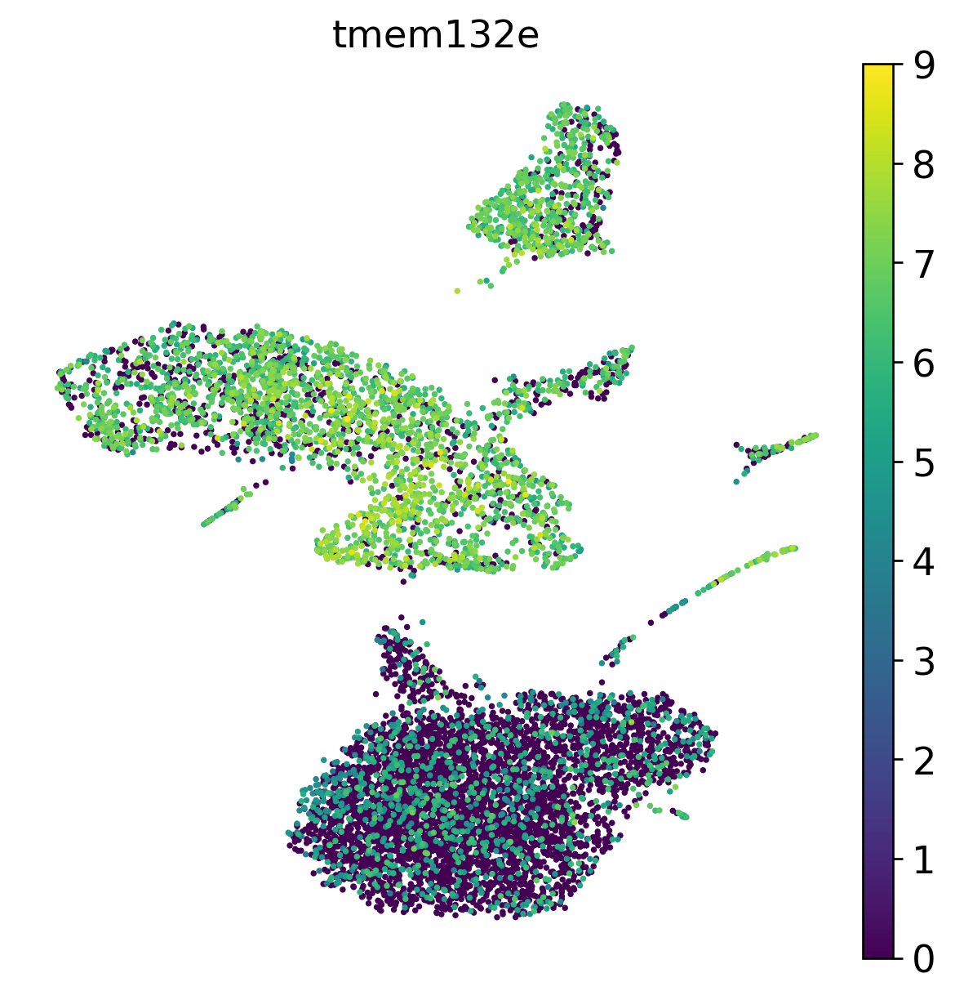

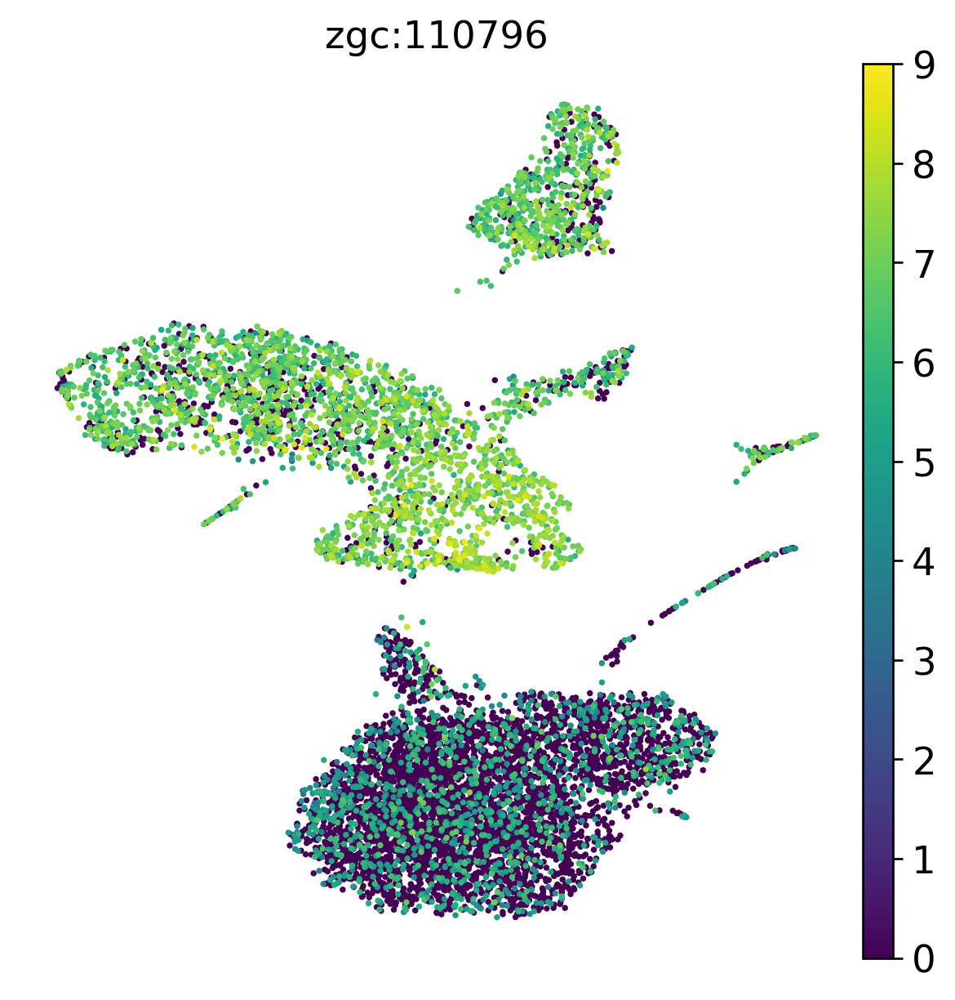

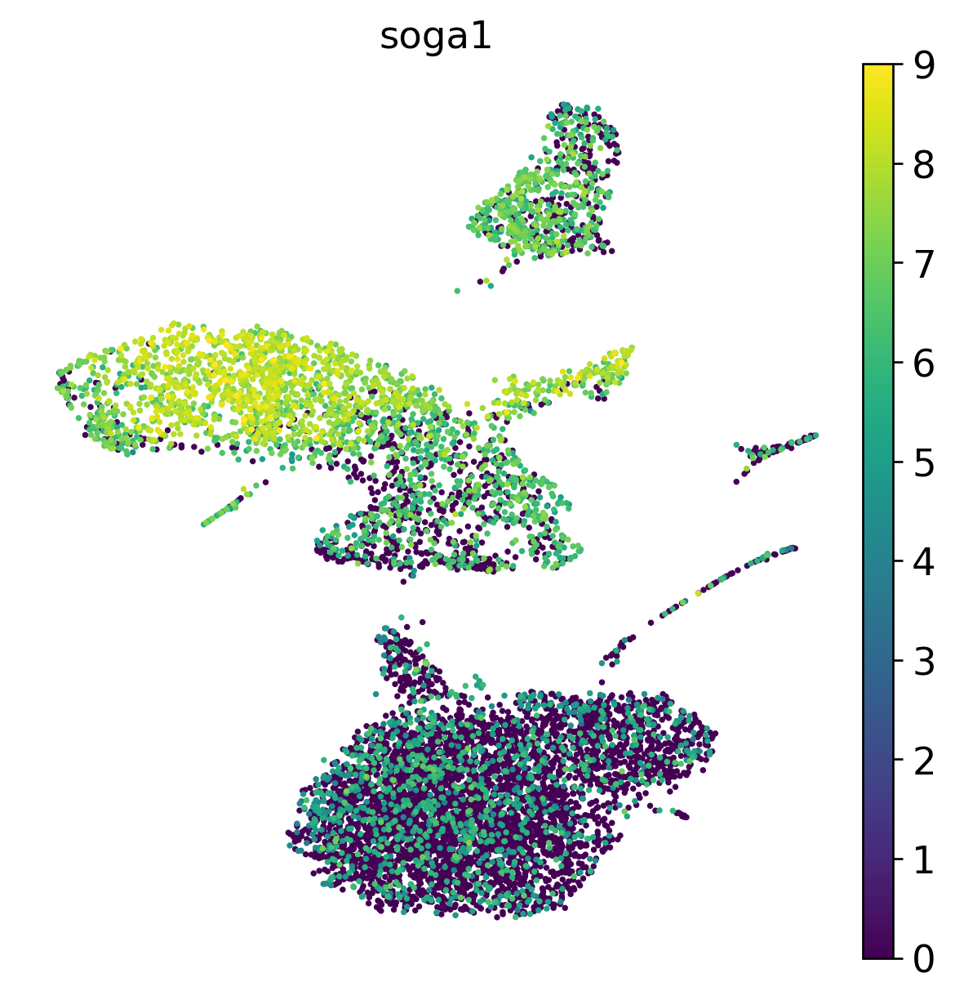

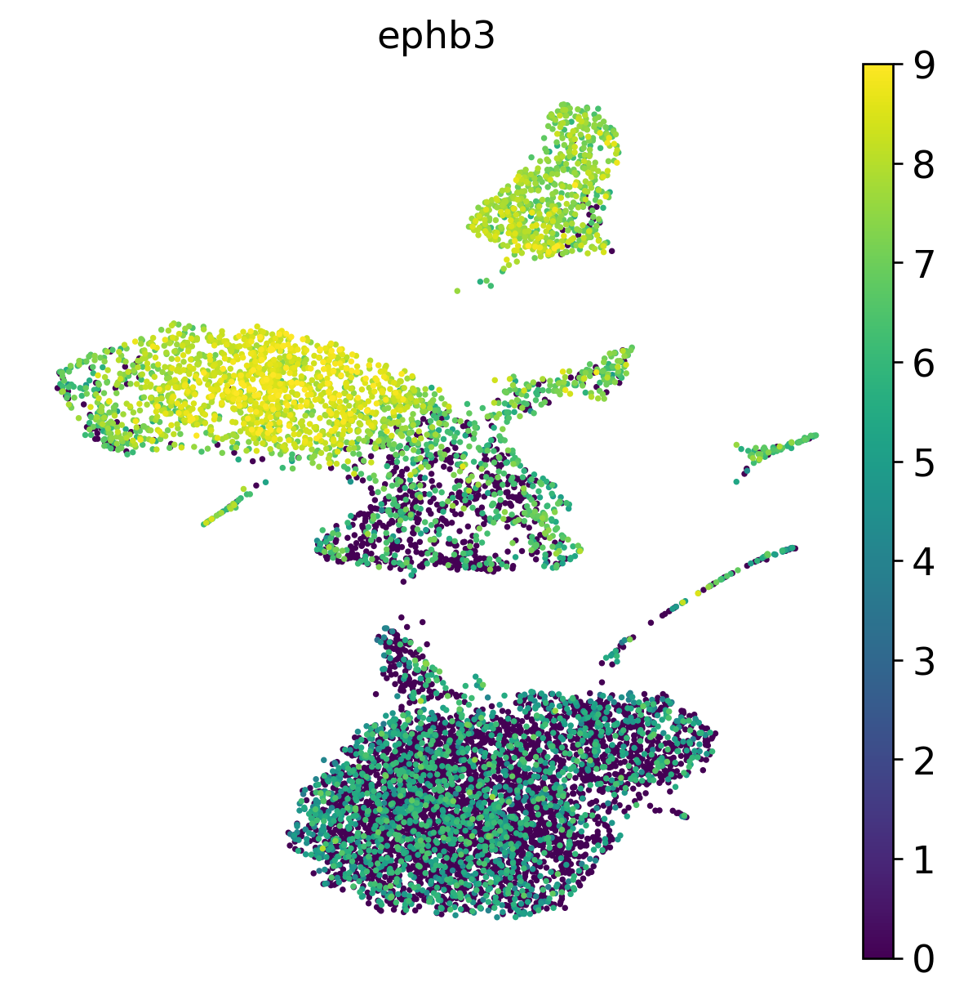

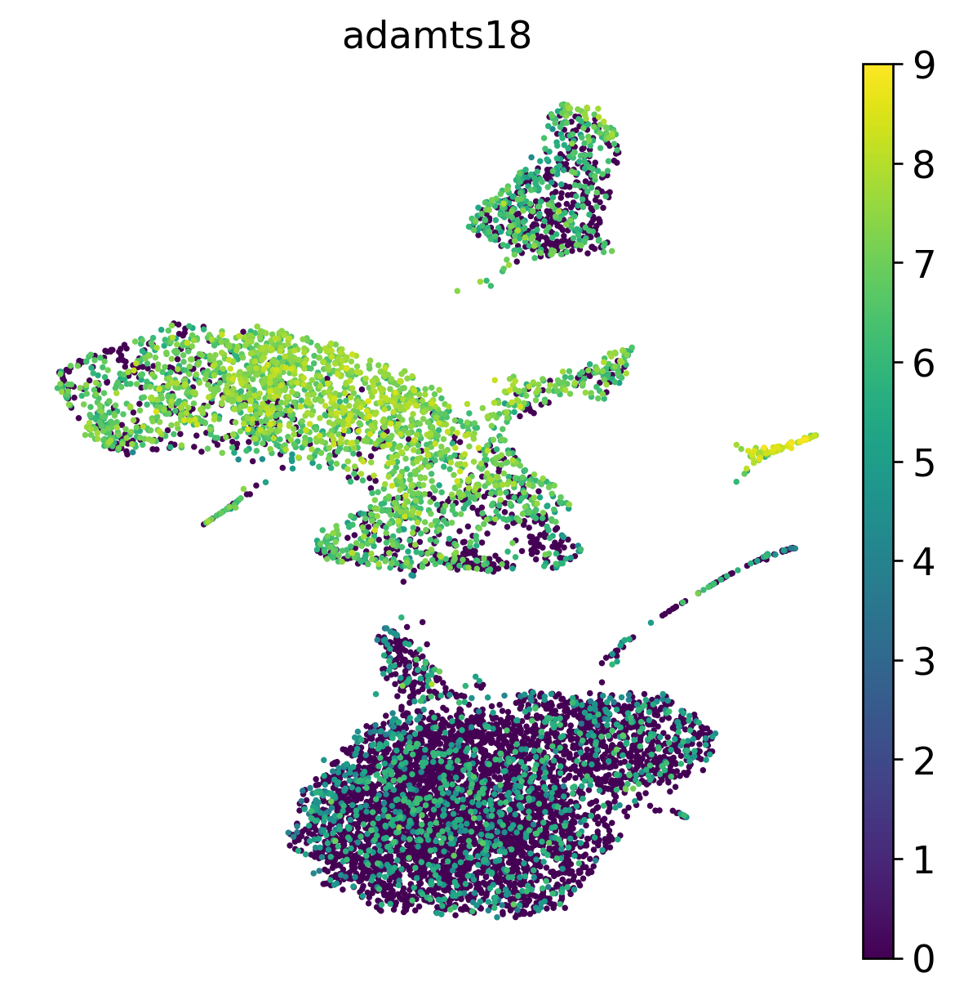

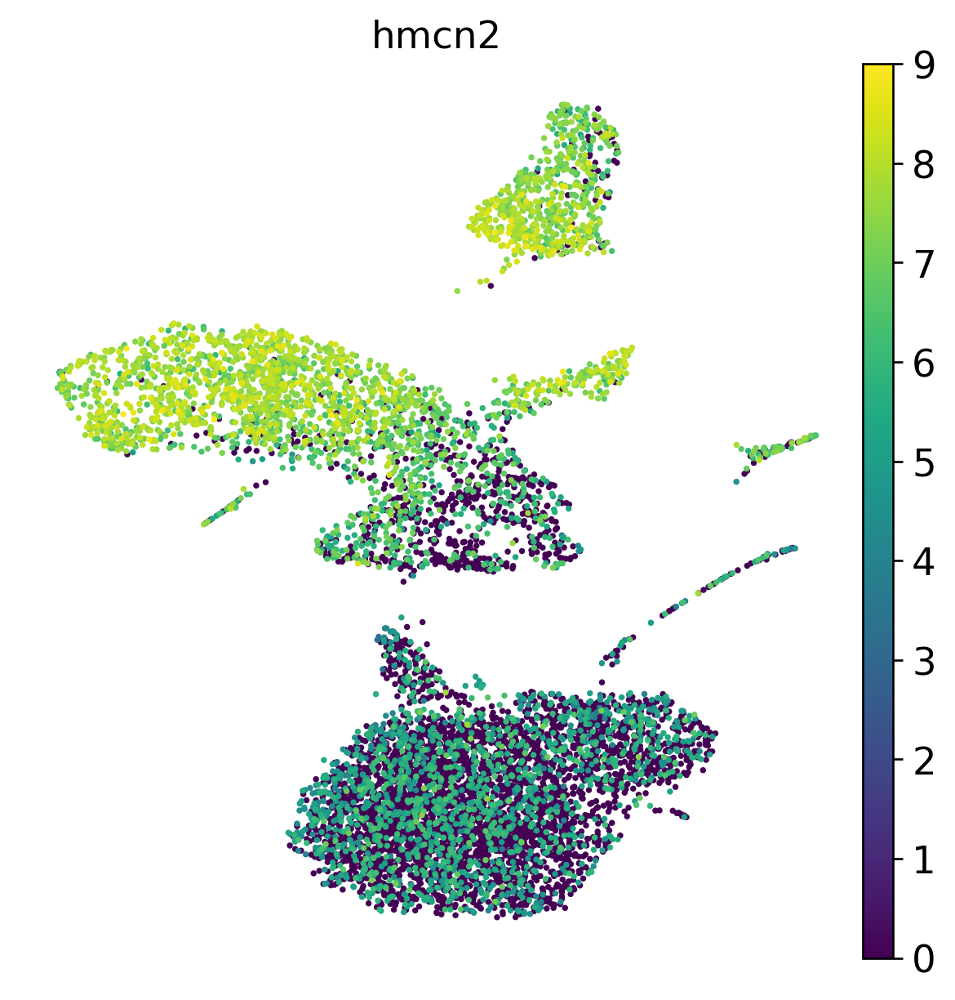

In [ ]:
sc.set_figure_params(figsize=(6, 6), dpi=120)

gene_list = ysl_genes_depleted[0:10]
#gene_list = pos_enrich_overlap['names'].head(10)
#gene_list = s_zf

for gene in gene_list:
    f = sc.pl.umap(adata, color=gene, s=20, frameon=False, vmax=9, layer='tpm', return_fig=True)
    #f.savefig('figs/'+gene+'.png', dpi=600, bbox_inches="tight")
    #f.savefig(base_path+'figs/'+gene+'.pdf', dpi=600, bbox_inches="tight")
    f.savefig(base_path+'figs/'+gene+'.png', dpi=600, bbox_inches="tight")



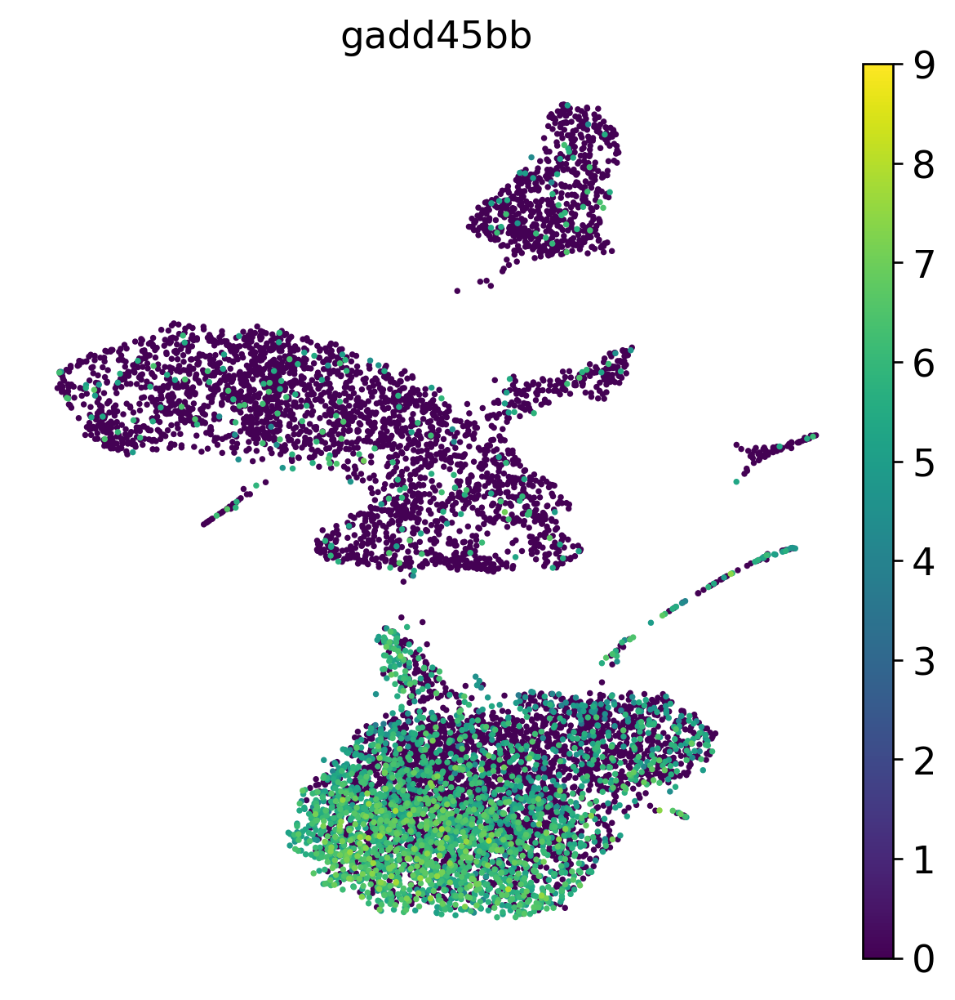

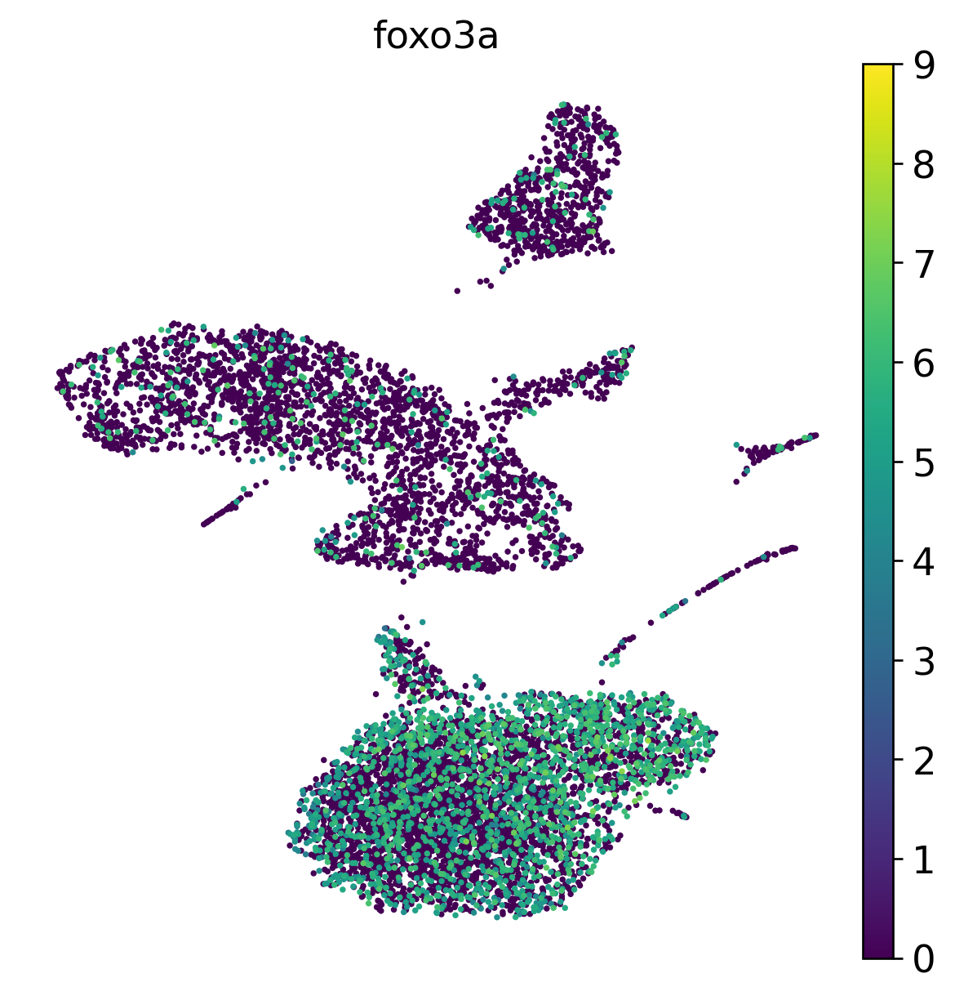

In [ ]:
for gene in ['gadd45bb','foxo3a']:
    f = sc.pl.umap(adata, color=gene, s=20, frameon=False, vmax=9, layer='tpm', return_fig=True)
    #f.savefig('figs/'+gene+'.png', dpi=600, bbox_inches="tight")
    #f.savefig(base_path+'figs/'+gene+'.pdf', dpi=600, bbox_inches="tight")
    f.savefig(base_path+'figs/'+gene+'.png', dpi=600, bbox_inches="tight")


## BMP Dotplots: ZMAP Annotations

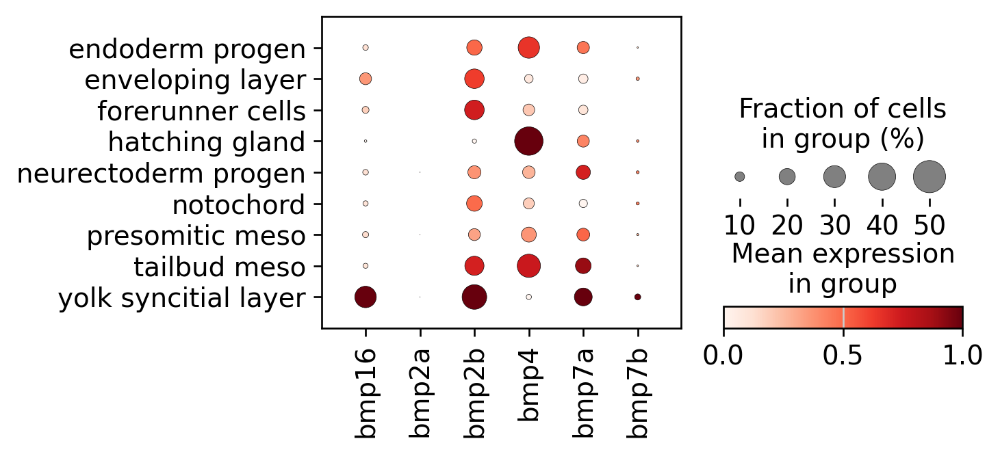

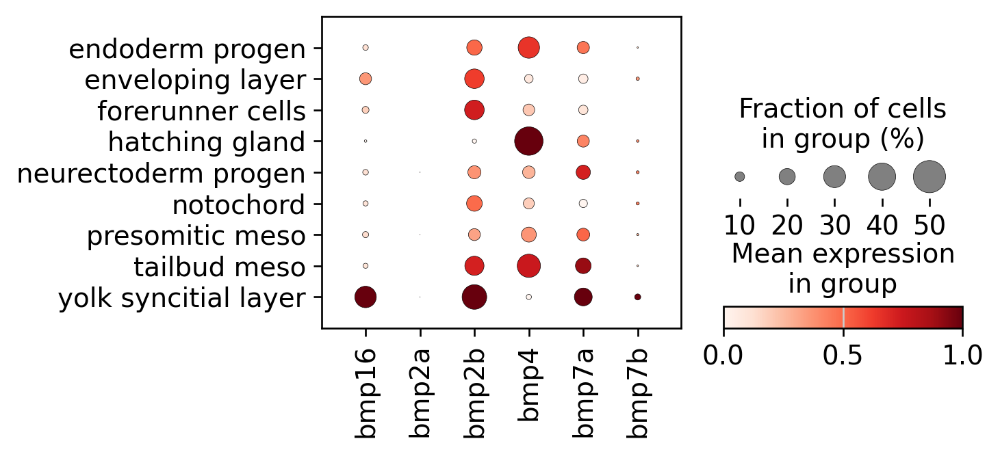

In [ ]:

sc.set_figure_params(figsize=(8, 8), dpi=120)

f1 = sc.pl.dotplot(adata,
                   var_names=['bmp16','bmp2a','bmp2b','bmp4','bmp7a','bmp7b'],
                   groupby='ZMAP_CellType_mapped',
                   layer='tpm',
                   cmap='Reds',
                   standard_scale='var',
                   dendrogram=False,
                   dot_min=0,
                   dot_max=0.5,
                   swap_axes=False,
                   figsize=(5, 2.5),   # width, height
                   return_fig=True)

f1.savefig(base_path+'figs/'+'YSL_zmap_dotplot_bmps.pdf', dpi=200, bbox_inches="tight")
f1.savefig(base_path+'figs/'+'YSL_zmap_dotplot_bmps.png', dpi=200, bbox_inches="tight")


## Save h5ad

In [ ]:
adata.write(base_path+'YSL-full_pp_norm_processed.h5ad')